<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_Thomos2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC for network intrusion detection: amplitude-encoded 4-qubit classifier (Thomos and Andronikos, 2026) step by step

This notebook re-implements, runs and checks the experiments of

> Angelos Thomos and Theodore Andronikos, "Evaluation of Variational Quantum Classifiers (VQC) for Cyberattack Detection in the NISQ Era",
> Journal of Sensor and Actuator Networks 15(4):67, 2026 (arXiv:2606.21715). DOI: https://doi.org/10.3390/jsan15040067

The notebook follows the arXiv v1 text (19 June 2026). The authors publish their code at
https://github.com/Angeloth1/Quantum-IDS-NSLKDD ; preprocessing, feature map and ansatz below are taken from that repository,
branch `revisionMDPI`, commit `af9127c5be83b00dc40bbef5725b95e38946e81c` (notebooks `main.ipynb`, `MCC.ipynb`,
`modelCircuitDesing.ipynb`, `multiclass_4class_fixed.ipynb`), and the branches `classificationFaild` / `SMOTE` for the 22-class and
4-class experiments of the paper's Section 8.

**What the notebook does.** It downloads the official 20 % research subset of NSL-KDD (`KDDTrain+_20Percent.txt`, 25,192 records),
rebuilds the paper's pipeline (dual stratified 80/20 split, target encoding, standardisation, PCA to 16 components, L2 normalisation),
amplitude-encodes the 16 numbers into 4 qubits with `raw_feature_vector`, trains the 24-parameter `RealAmplitudes` ansatz (`reps=5`)
with COBYLA and SPSA (500 iterations), and compares against Logistic Regression and the 4-node "Tiny MLP". It then reruns the two
multiclass experiments of Section 8 (imbalanced 4-family and balanced 22-label, in-sample) and checks every number the paper reports.
Two extensions are added because the paper's own limitation section asks for them: an ansatz-depth ablation and a noisy-hardware
inference test on an IBM fake backend.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned
Qiskit versions; if Colab asks to restart the session, restart and run all again. No GPU, no IBM account and no Hugging Face token
are needed (NSL-KDD comes from a public GitHub mirror).

**Runtime.** `FAST_MODE = True` runs in a few minutes (2 seeds, small Qiskit-VQC demonstration). `FAST_MODE = False` is the
committed full run (5 seeds, 3-seed depth ablation, larger Qiskit-VQC demonstration), roughly 30 to 40 minutes on a shared laptop CPU.

**What you get at the end.** The paper's Table 2 (binary report), the Tiny-MLP confusion matrix (Fig. 4), Table 3 and Fig. 5
(4 families), the 22-class report, the t-SNE of Fig. 1, the circuit of Figs. 2-3 drawn from the executed object, a side-by-side
table with a verdict per claim, a critical reading (including two implementation findings that change how the paper's
multiclass result should be read) and five exercises.

## The paper in one page

**Problem.** Detect malicious traffic in NSL-KDD with a small Variational Quantum Classifier and find out where it stops working.

**Decision.** Binary (normal = 0, attack = 1) for the headline result; 4 attack families (DoS, Probe, R2L, U2R) and 22 raw labels
as stress tests.

**Method.** Classical preprocessing -> amplitude encoding of 16 PCA components into 4 qubits (`raw_feature_vector`) -> `RealAmplitudes`
ansatz with `reps=5` (24 parameters) -> Z-basis measurement with Qiskit `VQC`'s default parity read-out -> cross-entropy loss minimised
with COBYLA (500 iterations) and, as a "methodological safeguard", with SPSA. Classical comparators: Logistic Regression and a 4-node
hidden-layer MLP fed with the same 16 numbers.

**Data.** NSL-KDD, official 20 % subset `KDDTrain+_20Percent` (25,192 records, 41 features + label + difficulty), 80/20 split into
20,155 training and 5,037 test records, stratified by label x `src_bytes` tercile; 8 label/size combinations that occur once are forced into
the training set. `KDDTest+` is deliberately not used.

**Preprocessing.** Target encoding of the categorical columns (fitted on training data), standard scaling, PCA with 16 components
(86.78 % explained variance), L2 normalisation per record.

**Claims checked here.**

| # | Claim in the paper | Where |
|---|---|---|
| C1 | Split sizes 20,155 / 5,037; 8 singleton combinations | Sec. 3.1, 4.1 |
| C2 | PCA-16 keeps 86.78 % of the variance | Sec. 4.2 |
| C3 | Ansatz has 24 trainable parameters | Sec. 5.2 |
| C4 | Binary VQC (COBYLA, 500 it.): accuracy 0.88, precision 0.90 / 0.86, recall 0.87 / 0.89 | Table 2 |
| C5 | SPSA plateaus at the same accuracy as COBYLA | Sec. 7.2 |
| C6 | Logistic Regression on the same inputs: 92 % | Sec. 7.3 |
| C7 | Tiny MLP (4 hidden nodes, 73 parameters, Adam, 1000 epochs): 97 % (confusion matrix 2613 / 77 / 78 / 2269) | Sec. 7.3, Fig. 4 |
| C8 | Imbalanced 4-family VQC: overall accuracy 91 %, R2L and U2R recall exactly 0 | Table 3, Fig. 5 |
| C9 | Balanced 22-label VQC, in-sample: accuracy 9 %, only `back` and `buffer_overflow` ever predicted (recall 1.00, precision about 0.10) | Sec. 8.2 |
| C10 | The ceiling is "not an optimisation artefact" but an effect of amplitude encoding | Sec. 6, 7.2, 9 |

## What follows the paper and what had to be chosen

The paper fixes dataset, split, encoding, ansatz, optimisers and iteration budget. It does not give seeds, shot count, initial
parameters, the exact training subset of the multiclass experiments, or the entanglement pattern actually executed. Where the paper is
silent this notebook makes a choice and marks it `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset file | `KDDTrain+_20Percent` (Kaggle copy) | Same file from the public GitHub mirror `defcom17/NSL_KDD` (fallback `jmnwong/NSL-KDD-Dataset`), 25,192 x 43 |
| Split | 80/20, label x `src_bytes` tercile, 8 singletons to train, 20,155 / 5,037 | Same code as the authors' `main.ipynb` (`random_state=42`); sizes asserted |
| Target-encoding labels | "posterior probability of an attack" (Sec. 4.2) | **Released code encodes a constant target** (it tests `label == 'normal.'` while the file says `'normal'`), so the four categorical columns become constant. `TARGET_ENCODING_MODE = "released_code"` reproduces the published 86.78 % variance; `"as_described"` encodes the real attack indicator and is run as a sensitivity check |
| Scaling, PCA | StandardScaler, PCA(16), fitted on train | Same; test transformed with the training fit |
| L2 normalisation | yes (Sec. 5.1) | Per record, after PCA (also applied to the classical baselines, which receive the identical vectors) |
| Circuit | `raw_feature_vector(16)` + `RealAmplitudes(4, reps=5)`, "linear" CNOTs | Same objects (function-style `real_amplitudes`); Qiskit's default entanglement is `reverse_linear` (CNOT order 2-3, 1-2, 0-1), which is what the authors' code runs; the drawn circuit is the executed one |
| Read-out | "parity of the bitstring" | Qiskit `VQC` default `interpret = x % 2` on the measured integer, i.e. the value of qubit 0 only (see the critical reading) |
| Sampler, shots | "statevector simulation" | `StatevectorSampler` with its default 1024 shots (the authors' `MCC.ipynb` does the same), so every loss evaluation carries shot noise |
| Initial parameters | not given | Qiskit default: uniform in [0, 1) from `algorithm_globals`, seed = run seed |
| Optimisers | COBYLA, SPSA, `maxiter=500` | `qiskit_machine_learning.optimizers.COBYLA` / `SPSA`, `maxiter=500`, defaults otherwise |
| Simulator | Qiskit `VQC` on 20,155 records (hours of CPU: the authors report 156 minutes for 200 COBYLA iterations) | A fast exact simulator that applies the same gate list to the whole training set at once and reproduces the shot noise (equivalence is tested against the real Qiskit `VQC` below); the real Qiskit `VQC` is also trained here on a subset |
| Seeds | one "representative run" | `RUN_SEEDS`: several initial points / shot-noise seeds, mean +- std |
| Imbalanced 4-family experiment | training set and budget not stated; Fig. 5 has 400 test records | Attack-only, natural class mix, random 1,000 training records, COBYLA 150, test = first 400 attack records of the held-out split (the authors' `SMOTE` branch uses the same 400) |
| Balanced 22-label experiment | 200 per label (oversampling), COBYLA, in-sample | Same; COBYLA 150 as in the authors' `classificationFaild` branch |
| Noise | none (ideal simulator) | Extension: inference on `FakeLimaV2` with Aer noise |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, seaborn.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in a few minutes. False: the committed full run (30 to 40 minutes on a laptop CPU).

SEED = 42                   # the authors use random_state=42 for the split; also the first run seed
DATA_DIR = "data"           # where KDDTrain+_20Percent.txt is cached (relative to the working directory)
IBM_TOKEN = ""              # unused: nothing here needs an IBM account (the noisy test uses a local fake backend)

# Pipeline switches
TARGET_ENCODING_MODE = "released_code"   # "released_code" (reproduces the paper's 86.78 %) or "as_described" (real attack indicator)

# Quantum model (Sec. 5, Table 1 of the paper)
N_QUBITS = 4
FEATURE_DIM = 2 ** N_QUBITS  # 16 principal components
REPS = 5                     # RealAmplitudes repetitions -> 24 parameters
SHOTS = 1024                 # CHOICE: StatevectorSampler default shot count
MAXITER = 500                # paper: COBYLA maximum 500 iterations; SPSA 500 iterations

# Repetitions
N_RUN_SEEDS = 2 if FAST_MODE else 5
RUN_SEEDS = [SEED + i for i in range(N_RUN_SEEDS)]

# Real Qiskit VQC demonstration on a subset (the paper's 20,155-record fit would take hours)
QK_N_TRAIN   = 50 if FAST_MODE else 150
QK_N_TEST    = 100 if FAST_MODE else 500
QK_MAXITER   = 15 if FAST_MODE else 50

# Multiclass experiments (Section 8)
IMB_TRAIN_N, IMB_TEST_N, IMB_MAXITER = 1000, 400, 150     # CHOICE: sizes not stated in the paper
BAL_PER_CLASS, BAL_MAXITER = 200, 150

# Extensions
DEPTH_REPS   = [1, 3, 5, 9]                  # ansatz depth ablation (reps=5 is the paper's)
DEPTH_SEEDS  = 1 if FAST_MODE else 3
NOISY_N      = 20 if FAST_MODE else 100      # test records run on the fake backend
TSNE_N       = 2000 if FAST_MODE else 5000   # records in the t-SNE of Fig. 1 (the paper does not state the number)

In [3]:
import os, io, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder, StandardScaler, normalize, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, accuracy_score)

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import Operator, Statevector
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA, SPSA
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.utils.loss_functions import CrossEntropyLoss

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| run seeds:", RUN_SEEDS, "| target encoding mode:", TARGET_ENCODING_MODE)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | run seeds: [42, 43, 44, 45, 46] | target encoding mode: released_code


## 1. The NSL-KDD data

NSL-KDD (Tavallaee et al., 2009) removes the duplicate records that biased KDD Cup '99. Each record describes one network connection with
41 features (basic: duration, protocol, byte counts; content: failed logins, root shells; traffic: connection counts and error rates in a
2-second or 100-connection window) plus a label (`normal` or one of 21 attack names) and a difficulty score that the paper drops. The paper uses
the official 20 % research subset, 25,192 records. (The paper says "22 attack categories"; the 22 distinct label values are in fact `normal` plus 21 attacks.)

The cell downloads the file from a public GitHub mirror into `DATA_DIR`; a second run reads the cache. If both mirrors are unreachable,
upload `KDDTrain+_20Percent.txt` into `DATA_DIR` by hand.

In [4]:
COLS = ['duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent','hot','num_failed_logins',
        'logged_in','num_compromised','root_shell','su_attempted','num_root','num_file_creations','num_shells','num_access_files',
        'num_outbound_cmds','is_host_login','is_guest_login','count','srv_count','serror_rate','srv_serror_rate','rerror_rate',
        'srv_rerror_rate','same_srv_rate','diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count',
        'dst_host_same_srv_rate','dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
        'dst_host_serror_rate','dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty_level']

# Attack family of every label that occurs in the 20 % subset (taxonomy of Tavallaee et al.; same grouping as the authors' notebooks)
FAMILY = {'normal': 'normal',
          'neptune': 'dos', 'smurf': 'dos', 'back': 'dos', 'teardrop': 'dos', 'pod': 'dos', 'land': 'dos',
          'ipsweep': 'probe', 'satan': 'probe', 'portsweep': 'probe', 'nmap': 'probe',
          'warezclient': 'r2l', 'guess_passwd': 'r2l', 'warezmaster': 'r2l', 'imap': 'r2l', 'multihop': 'r2l', 'phf': 'r2l',
          'ftp_write': 'r2l', 'spy': 'r2l',
          'buffer_overflow': 'u2r', 'rootkit': 'u2r', 'loadmodule': 'u2r'}
FAM_ORDER = ['normal', 'dos', 'probe', 'r2l', 'u2r']
FAM_ID = {'dos': 0, 'probe': 1, 'r2l': 2, 'u2r': 3}          # class ids of the 4-family experiment (DoS, Probe, R2L, U2R)
FAM_NAMES = ['DoS', 'Probe', 'R2L', 'U2R']

DATA_PATH = os.path.join(DATA_DIR, "KDDTrain+_20Percent.txt")
URLS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B_20Percent.txt",
        "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B_20Percent.txt"]

def load_nslkdd():
    if not os.path.exists(DATA_PATH):
        import requests
        for u in URLS:
            try:
                r = requests.get(u, timeout=120); r.raise_for_status()
                if len(r.content) < 3_000_000: raise ValueError("file too small")
                open(DATA_PATH, "wb").write(r.content); print("downloaded", u); break
            except Exception as e:
                print("download failed:", u, type(e).__name__, e)
        else:
            raise RuntimeError(f"Could not download NSL-KDD; upload KDDTrain+_20Percent.txt to {DATA_DIR}/")
    else:
        print("using cached", DATA_PATH)
    return pd.read_csv(DATA_PATH, names=COLS)

df = load_nslkdd()
assert df.shape == (25192, 43), df.shape
print("shape:", df.shape, "(paper: 25,192 records; 41 features + label + difficulty)")
df["family"] = df["label"].map(FAMILY)                       # helper column used for colouring and the 4-family task
assert df["family"].notna().all(), df.loc[df["family"].isna(), "label"].unique()
print("distinct label values:", df["label"].nunique())

using cached data\KDDTrain+_20Percent.txt


shape: (25192, 43) (paper: 25,192 records; 41 features + label + difficulty)
distinct label values: 22


## 2. Split and preprocessing (the paper's Sections 3.1, 4.1 and 4.2)

**Dual stratification.** A split stratified by label alone would, for the 22 labels (several with 1 to 6 records), be unstable, so the authors
stratify by `label + src_bytes tercile` (low / medium / high from equal-frequency quantiles). Combinations with fewer than two records cannot be
stratified; they are first collapsed to the bare label, and the 8 labels that still occur once (`portsweep`, `ftp_write`, `warezmaster`, `land`,
`loadmodule`, `satan`, `spy`, `ipsweep`) are put into the training set by hand. The remaining records are split 80/20 with `random_state=42`.

**Target encoding.** Each categorical column (`protocol_type`, `service`, `flag` and the new `src_bytes_cat`) is replaced by a smoothed
attack rate. The encoder is fitted on training data only.

**One thing to know before running it.** The authors' `main.ipynb` builds the encoder's target with `np.where(yTrain == 'normal.', 0, 1)`.
The label in the file is `normal` (no full stop), so that target is 1 for every record and the encoded categorical columns are the constant 1.0
(zero after scaling): in the published pipeline the categorical columns carry no information at all. This is what produced the paper's reported
86.78 % explained variance, and the notebook shows that below. `TARGET_ENCODING_MODE = "released_code"` reproduces it so the paper's numbers can be
compared like for like; `"as_described"` encodes the true attack indicator, and the notebook runs that variant too as a sensitivity check.

**Scaling, PCA, L2.** StandardScaler -> PCA with 16 components -> each record divided by its Euclidean norm so that it is a valid amplitude vector.
All of these are fitted on the training split only.

In [5]:
CAT_COLS = ['protocol_type', 'service', 'flag', 'src_bytes_cat']
DROP_COLS = ['label', 'difficulty_level', 'strat_col', 'family']

def paper_split(df_in):
    # Dual stratification + singleton injection, as in the authors' main.ipynb (random_state=42 as in the paper).
    d = df_in.copy()
    d['src_bytes_cat'] = pd.qcut(d['src_bytes'], q=4, duplicates='drop', labels=['low', 'medium', 'high'])
    d['strat_col'] = d['label'].astype(str) + "_" + d['src_bytes_cat'].astype(str)
    counts = d['strat_col'].value_counts()
    rare = counts[counts < 2].index
    mask = d['strat_col'].isin(rare)
    d.loc[mask, 'strat_col'] = d.loc[mask, 'label']
    final = d['strat_col'].value_counts()
    singles = final[final < 2]
    single_mask = d['strat_col'].isin(singles.index)
    majority, singleton_rows = d[~single_mask], d[single_mask]
    train_major, test_set = train_test_split(majority, test_size=0.2, random_state=42, stratify=majority['strat_col'])
    train_set = pd.concat([train_major, singleton_rows])
    return train_set, test_set, list(singles.index)

train_set, test_set, singletons = paper_split(df)
print(f"train {train_set.shape[0]:,} | test {test_set.shape[0]:,}   (paper: 20,155 / 5,037)")
print(f"singleton label/size combinations forced into training: {len(singletons)} {singletons}   (paper: 8)")
assert (len(train_set), len(test_set), len(singletons)) == (20155, 5037, 8)

def build_features(train_set, test_set, mode):
    # Target encoding -> StandardScaler -> PCA(16) -> L2, everything fitted on the training split only.
    Xtr, Xte = train_set.drop(columns=DROP_COLS), test_set.drop(columns=DROP_COLS)
    if mode == "released_code":
        y_enc = np.ones(len(train_set), dtype=int)     # the authors' np.where(y == 'normal.', 0, 1) is 1 everywhere (label is 'normal')
    elif mode == "as_described":
        y_enc = (train_set['label'] != 'normal').astype(int).to_numpy()
    else:
        raise ValueError(mode)
    enc = TargetEncoder(target_type='binary', smooth='auto', random_state=SEED)   # CHOICE: seed for the encoder's cross-fitting
    tr_cat = enc.fit_transform(Xtr[CAT_COLS], y_enc)
    te_cat = enc.transform(Xte[CAT_COLS])
    Xtr_f = pd.concat([Xtr.drop(columns=CAT_COLS), pd.DataFrame(tr_cat, columns=CAT_COLS, index=Xtr.index)], axis=1)
    Xte_f = pd.concat([Xte.drop(columns=CAT_COLS), pd.DataFrame(te_cat, columns=CAT_COLS, index=Xte.index)], axis=1)
    scaler = StandardScaler().fit(Xtr_f)
    Xtr_s, Xte_s = scaler.transform(Xtr_f), scaler.transform(Xte_f)
    pca = PCA(n_components=FEATURE_DIM, random_state=SEED).fit(Xtr_s)
    Xtr_p, Xte_p = pca.transform(Xtr_s), pca.transform(Xte_s)
    return dict(mode=mode, feature_names=list(Xtr_f.columns), Xtr_s=Xtr_s, Xte_s=Xte_s,
                Xtr_pca=Xtr_p, Xte_pca=Xte_p, Xtr=normalize(Xtr_p), Xte=normalize(Xte_p),
                ev=float(pca.explained_variance_ratio_.sum()), ev_curve=np.cumsum(pca.explained_variance_ratio_),
                enc_train_example=tr_cat[:3].round(3))

P = build_features(train_set, test_set, TARGET_ENCODING_MODE)
P["ytr"] = (train_set['label'] != 'normal').astype(int).to_numpy()      # 0 = normal, 1 = attack
P["yte"] = (test_set['label'] != 'normal').astype(int).to_numpy()
P["ytr_label"], P["yte_label"] = train_set['label'].to_numpy(), test_set['label'].to_numpy()
P["ytr_family"], P["yte_family"] = train_set['family'].to_numpy(), test_set['family'].to_numpy()

print(f"mode = {P['mode']}: first three encoded categorical rows (train):\n{P['enc_train_example']}")
print(f"PCA-16 explained variance (fitted on train): {P['ev']:.2%}   (paper: 86.78 %)")
print(f"features entering PCA: {len(P['feature_names'])} | model input per record: {P['Xtr'].shape[1]} numbers, unit L2 norm: "
      f"{np.allclose(np.linalg.norm(P['Xtr'], axis=1), 1)}")
print(f"attack share: train {P['ytr'].mean():.3f} | test {P['yte'].mean():.3f}")

train 20,155 | test 5,037   (paper: 20,155 / 5,037)
singleton label/size combinations forced into training: 8 ['portsweep', 'ftp_write', 'warezmaster', 'land', 'loadmodule', 'satan', 'spy', 'ipsweep']   (paper: 8)


mode = released_code: first three encoded categorical rows (train):
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
PCA-16 explained variance (fitted on train): 86.78%   (paper: 86.78 %)
features entering PCA: 42 | model input per record: 16 numbers, unit L2 norm: True
attack share: train 0.466 | test 0.466


## Dataset Exploration and Visualisation

Everything in this section is drawn from the real NSL-KDD records (no synthetic points). The model's input is amplitude-encoded, so
there is no angle scaling to [0, pi]; the coordinates the circuit actually receives are the L2-normalised PCA vectors, drawn in the last panel.

In [6]:
print("=== Raw data ===")
print("shape                   :", df.drop(columns="family").shape)
print("dtypes                  :", {str(k): v for k, v in df.drop(columns="family").dtypes.astype(str).value_counts().items()})
print("feature names (41)      :", [c for c in COLS if c not in ("label", "difficulty_level")])
print("categorical features    :", ['protocol_type', 'service', 'flag'], "| numeric:", 38)
print("missing values          :", int(df.isna().sum().sum()))
print("duplicated rows         :", int(df.duplicated().sum()))
print("\noriginal label values and counts (22 distinct):")
lab = df["label"].value_counts()
display(pd.DataFrame({"count": lab, "share %": (100 * lab / len(df)).round(2), "family": [FAMILY[l] for l in lab.index]}).T)
print("\nfamily counts :", df["family"].value_counts().reindex(FAM_ORDER).to_dict())
print("\ntrain / test split (the paper's 80/20):")
split_tab = pd.DataFrame({"train": train_set["family"].value_counts().reindex(FAM_ORDER),
                          "test": test_set["family"].value_counts().reindex(FAM_ORDER)})
display(split_tab.T)

=== Raw data ===
shape                   : (25192, 43)
dtypes                  : {'int64': 24, 'float64': 15, 'str': 4}
feature names (41)      : ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
categorical features    : ['protocol_type', 'service', 'flag'] | numeric: 38


missing values          : 0


duplicated rows         : 0

original label values and counts (22 distinct):


label,normal,neptune,ipsweep,satan,portsweep,smurf,nmap,back,teardrop,warezclient,pod,guess_passwd,warezmaster,buffer_overflow,imap,rootkit,multihop,phf,ftp_write,land,loadmodule,spy
count,13449,8282,710,691,587,529,301,196,188,181,38,10,7,6,5,4,2,2,1,1,1,1
share %,53.39,32.88,2.82,2.74,2.33,2.1,1.19,0.78,0.75,0.72,0.15,0.04,0.03,0.02,0.02,0.02,0.01,0.01,0.0,0.0,0.0,0.0
family,normal,dos,probe,probe,probe,dos,probe,dos,dos,r2l,dos,r2l,r2l,u2r,r2l,u2r,r2l,r2l,r2l,dos,u2r,r2l



family counts : {'normal': 13449, 'dos': 9234, 'probe': 2289, 'r2l': 209, 'u2r': 11}

train / test split (the paper's 80/20):


family,normal,dos,probe,r2l,u2r
train,10759,7386,1832,168,10
test,2690,1848,457,41,1


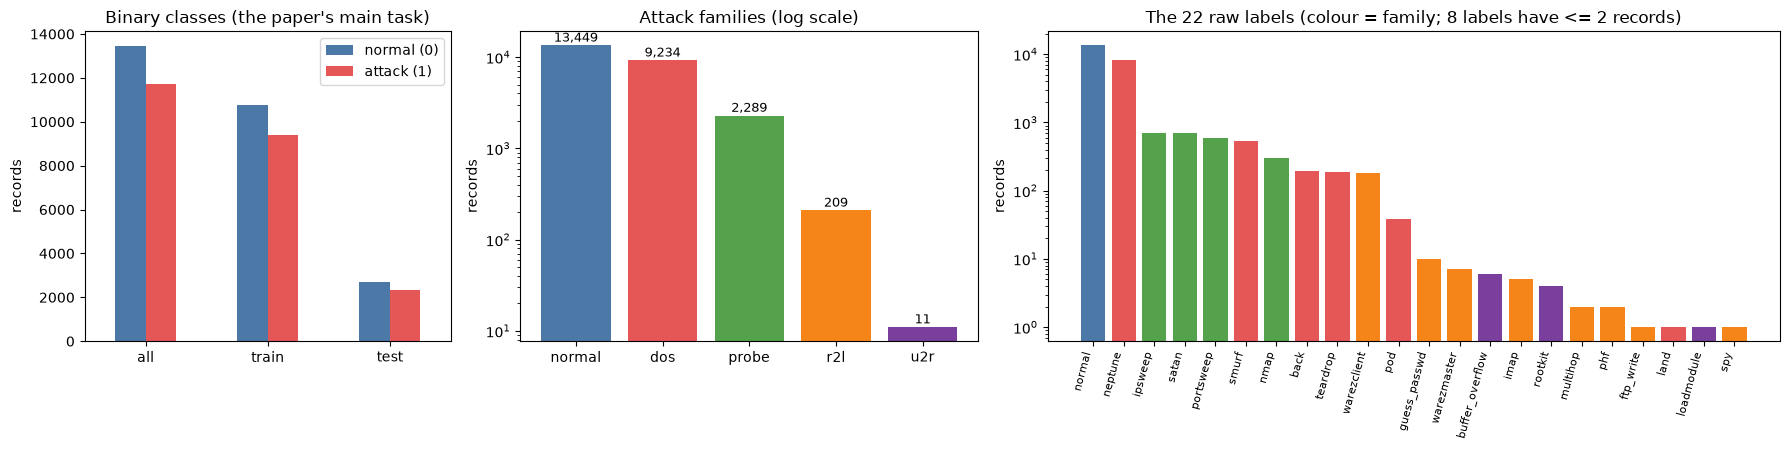

In [7]:
PAL = {'normal': '#4C78A8', 'dos': '#E45756', 'probe': '#54A24B', 'r2l': '#F58518', 'u2r': '#7A3E9D'}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [0.8, 1, 1.6]})
# (a) binary classes, full data and the two splits
b = pd.DataFrame({"all": [(df.label == "normal").sum(), (df.label != "normal").sum()],
                  "train": [(train_set.label == "normal").sum(), (train_set.label != "normal").sum()],
                  "test": [(test_set.label == "normal").sum(), (test_set.label != "normal").sum()]}, index=["normal (0)", "attack (1)"])
b.T.plot.bar(ax=axes[0], color=["#4C78A8", "#E45756"], rot=0); axes[0].set_title("Binary classes (the paper's main task)"); axes[0].set_ylabel("records")
# (b) families
fc = df["family"].value_counts().reindex(FAM_ORDER)
axes[1].bar(fc.index, fc.values, color=[PAL[f] for f in fc.index]); axes[1].set_yscale("log")
for i, v in enumerate(fc.values): axes[1].text(i, v * 1.1, f"{v:,}", ha="center", fontsize=9)
axes[1].set_title("Attack families (log scale)"); axes[1].set_ylabel("records")
# (c) the 22 raw labels
lab = df["label"].value_counts()
axes[2].bar(range(len(lab)), lab.values, color=[PAL[FAMILY[l]] for l in lab.index]); axes[2].set_yscale("log")
axes[2].set_xticks(range(len(lab))); axes[2].set_xticklabels(lab.index, rotation=75, ha="right", fontsize=8)
axes[2].set_title("The 22 raw labels (colour = family; 8 labels have <= 2 records)"); axes[2].set_ylabel("records")
plt.tight_layout(); plt.show()

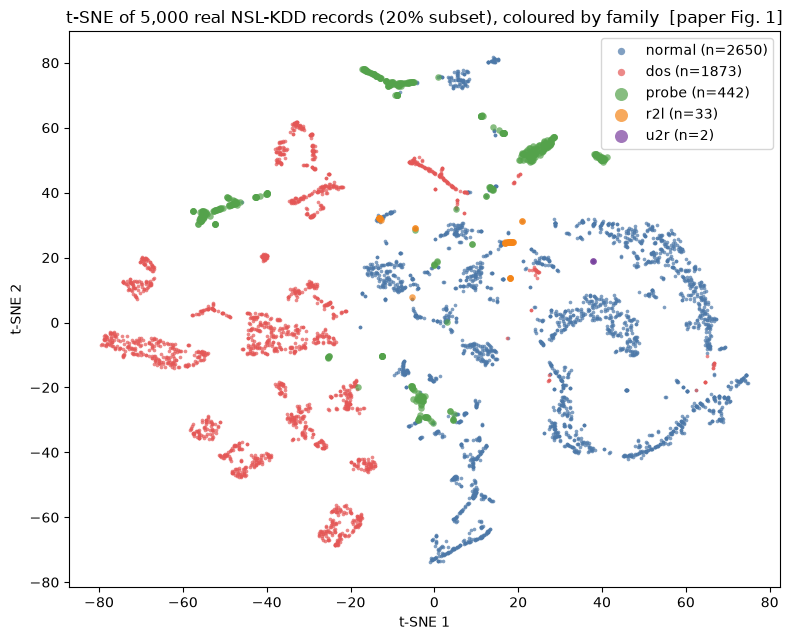

t-SNE took 82 s


In [8]:
# The paper's Figure 1: t-SNE of the 20 % subset coloured by family (categoricals label-encoded, features standardised).
t0 = time.time()
samp = df.sample(n=TSNE_N, random_state=SEED)
Xv = samp.drop(columns=["label", "difficulty_level", "family"]).copy()
for c in ["protocol_type", "service", "flag"]:
    Xv[c] = LabelEncoder().fit_transform(Xv[c])
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(StandardScaler().fit_transform(Xv))
fig, ax = plt.subplots(figsize=(8, 6.5))
for fam in FAM_ORDER:                                    # rare families drawn last, so they stay visible
    m = (samp["family"] == fam).to_numpy()
    ax.scatter(Z[m, 0], Z[m, 1], s=7 if fam in ("normal", "dos") else 22, alpha=0.7, c=PAL[fam], label=f"{fam} (n={m.sum()})", linewidths=0)
ax.set_title(f"t-SNE of {TSNE_N:,} real NSL-KDD records (20% subset), coloured by family  [paper Fig. 1]")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()
print(f"t-SNE took {time.time()-t0:.0f} s")

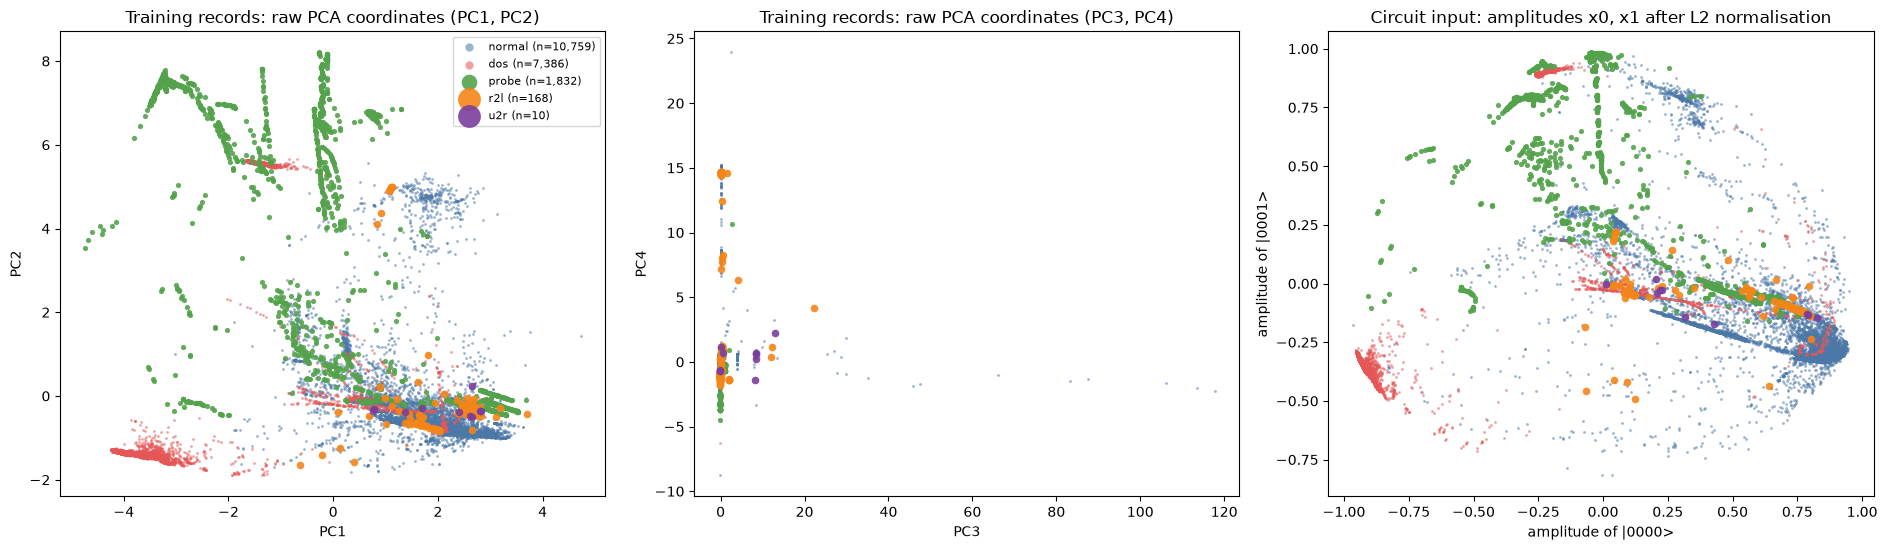

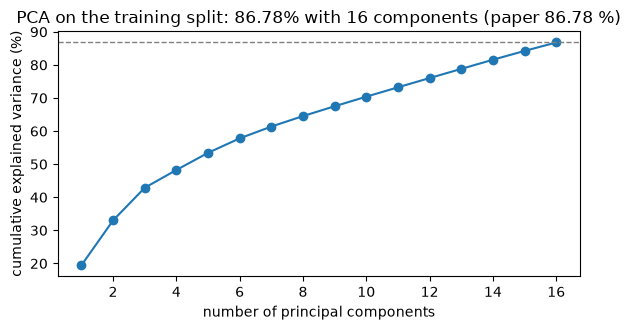

In [9]:
# What the classifier actually sees: PCA coordinates fitted on the TRAINING split, coloured by ground-truth family,
# then the unit-norm amplitude vector that is loaded into the 4 qubits.
famtr = P["ytr_family"]
order = ['normal', 'dos', 'probe', 'r2l', 'u2r']
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
def scatter(ax, A, B, title, xl, yl):
    for fam in order:
        m = famtr == fam
        ax.scatter(A[m], B[m], s=4 if fam in ("normal", "dos") else (14 if fam == "probe" else 30), alpha=0.55 if fam in ("normal", "dos") else 0.9,
                   c=PAL[fam], label=f"{fam} (n={m.sum():,})", linewidths=0)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
scatter(axes[0], P["Xtr_pca"][:, 0], P["Xtr_pca"][:, 1], "Training records: raw PCA coordinates (PC1, PC2)", "PC1", "PC2")
scatter(axes[1], P["Xtr_pca"][:, 2], P["Xtr_pca"][:, 3], "Training records: raw PCA coordinates (PC3, PC4)", "PC3", "PC4")
scatter(axes[2], P["Xtr"][:, 0], P["Xtr"][:, 1], "Circuit input: amplitudes x0, x1 after L2 normalisation", "amplitude of |0000>", "amplitude of |0001>")
axes[0].legend(markerscale=3, loc="best", fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(1, 17), 100 * P["ev_curve"], "o-"); ax.axhline(86.78, color="gray", ls="--", lw=1)
ax.set_xlabel("number of principal components"); ax.set_ylabel("cumulative explained variance (%)")
ax.set_title(f"PCA on the training split: {P['ev']:.2%} with 16 components (paper 86.78 %)"); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper's circuit has three stages: amplitude loading of the 16 numbers (`raw_feature_vector(16)`, fixed), the trainable
`RealAmplitudes` ansatz with `reps=5` (24 parameters) and Z-basis measurement of all four qubits. The cell below builds the Qiskit `VQC`
exactly as in the authors' `MCC.ipynb` and draws `vqc.circuit`, the object whose copies the sampler executes. Details the paper leaves open
and that are fixed by the code:

* **Entanglement.** The text says "linear"; `real_amplitudes(4, reps=5)` uses Qiskit's default `reverse_linear` (CNOT(2,3), CNOT(1,2), CNOT(0,1) in every repetition), which is what the authors' notebook executes. The drawing shows it.
* **State preparation.** `raw_feature_vector` is a parameterised state-preparation block; the sampler decomposes it into resets, rotations and CNOTs when it binds a record. The second drawing shows that decomposition for one real test record.
* **Measurement.** `measure_all()` adds one classical bit per qubit; `VQC` maps the integer outcome `k` to the class `k mod 2` (see Section 3).
* **One architecture.** Binary, 4-family and 22-label experiments all use this single circuit; they differ only in the read-out map. The depth ablation of Section 9 uses the same circuit family with other `reps`, drawn at the end of this section.

In [10]:
fm = raw_feature_vector(FEATURE_DIM)
ansatz = real_amplitudes(N_QUBITS, reps=REPS)                       # 24 parameters; default entanglement reverse_linear
vqc_demo = VQC(feature_map=fm, ansatz=ansatz, optimizer=COBYLA(maxiter=1),
               sampler=StatevectorSampler(default_shots=SHOTS, seed=SEED))
exec_circ = vqc_demo.circuit                                         # the circuit the sampler runs (feature map + ansatz)
meas_circ = exec_circ.measure_all(inplace=False)                     # plus the final Z-basis measurement of the 4 qubits

# Decompositions
sample_x = P["Xte"][0]
bound_fm = fm.assign_parameters(dict(zip(fm.parameters, sample_x)))
fm_flat = transpile(bound_fm, basis_gates=["u", "cx"], optimization_level=0)         # what state preparation costs in gates
ans_flat = transpile(ansatz, basis_gates=["ry", "cx"], optimization_level=0)         # the gate list used by the fast simulator below
full_flat = transpile(meas_circ.assign_parameters({**dict(zip(fm.parameters, sample_x)), **dict(zip(ansatz.parameters, np.zeros(ansatz.num_parameters)))}),
                      basis_gates=["u", "cx"], optimization_level=0)

arch = pd.DataFrame([
    ["amplitude loader raw_feature_vector(16), bound to one record, in {u, cx}", fm_flat.num_qubits, fm_flat.depth(), 0, dict(fm_flat.count_ops())],
    ["ansatz real_amplitudes(4, reps=5), in {ry, cx}", ans_flat.num_qubits, ans_flat.depth(), ansatz.num_parameters, dict(ans_flat.count_ops())],
    ["whole VQC circuit incl. measurement, in {u, cx}", full_flat.num_qubits, full_flat.depth(), ansatz.num_parameters, dict(full_flat.count_ops())],
], columns=["circuit", "qubits", "depth", "trainable parameters", "gate counts"])
display(arch)
print("input parameters of the feature map:", fm.num_parameters, "| weight parameters of the ansatz:", ansatz.num_parameters, "(paper: 24)")
assert ansatz.num_parameters == 24 and exec_circ.num_qubits == 4

,circuit,qubits,depth,trainable parameters,gate counts
0,"amplitude loader raw_feature_vector(16), bound...",4,24,0,"{'u': 15, 'cx': 11, 'reset': 4}"
1,"ansatz real_amplitudes(4, reps=5), in {ry, cx}",4,17,24,"{'ry': 24, 'cx': 15}"
2,"whole VQC circuit incl. measurement, in {u, cx}",4,40,24,"{'u': 39, 'cx': 26, 'reset': 4, 'measure': 4, ..."


input parameters of the feature map: 16 | weight parameters of the ansatz: 24 (paper: 24)


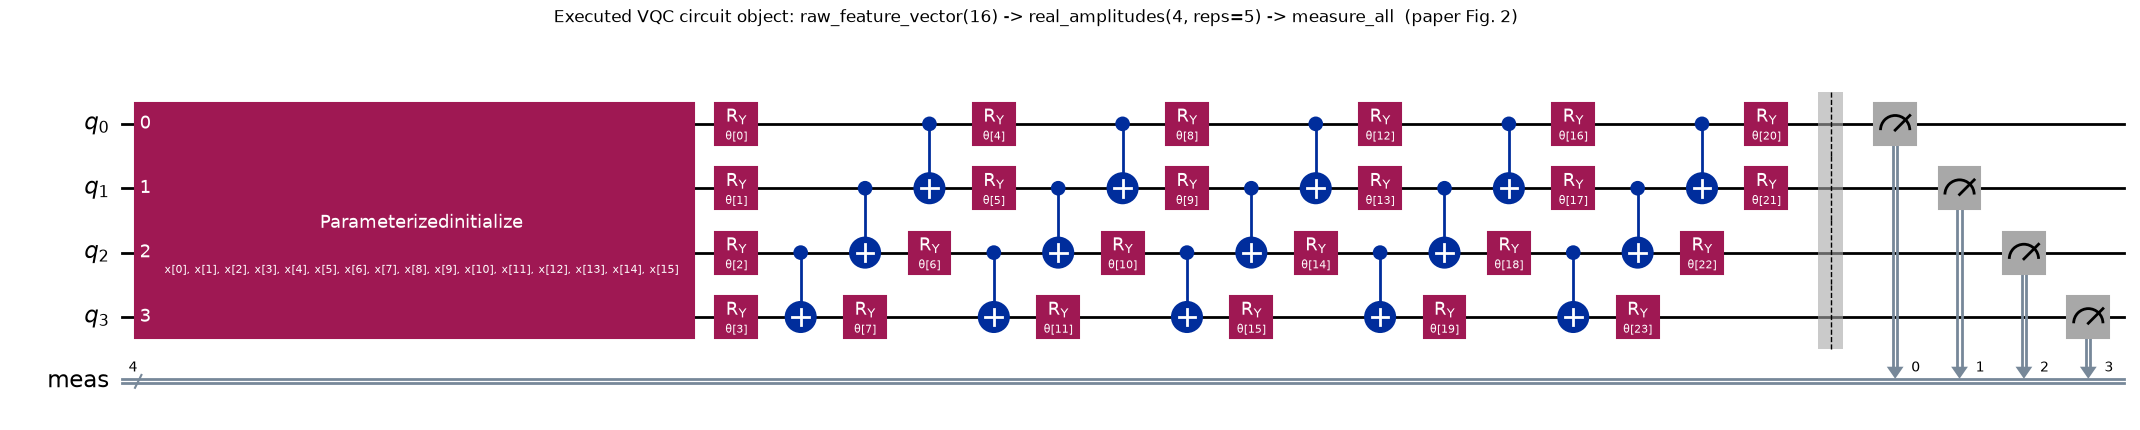

In [11]:
# Figure A: the executed circuit object (feature map block + ansatz block + measurement)
fig = meas_circ.draw("mpl", fold=40, style="iqp")
fig.suptitle("Executed VQC circuit object: raw_feature_vector(16) -> real_amplitudes(4, reps=5) -> measure_all  (paper Fig. 2)", y=1.02)
display(fig); plt.close(fig)

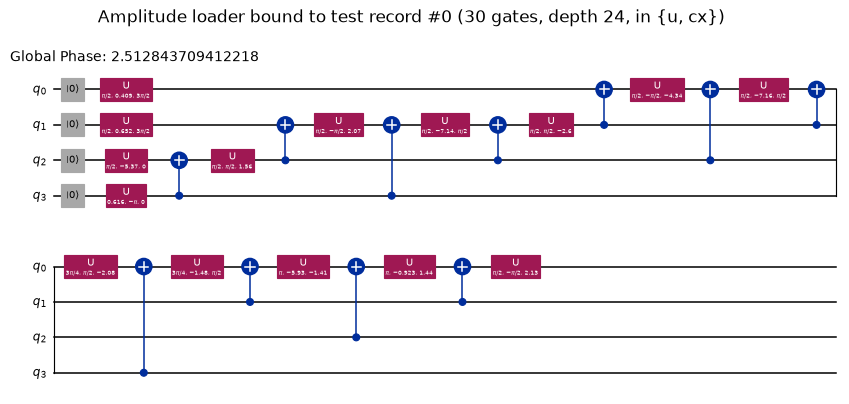

In [12]:
# Figure B: the state preparation for one real test record, decomposed into elementary gates (what the simulator really runs)
fig = fm_flat.draw("mpl", fold=22, style="iqp", scale=0.55)
fig.suptitle(f"Amplitude loader bound to test record #0 ({fm_flat.size()} gates, depth {fm_flat.depth()}, in {{u, cx}})", y=1.0)
display(fig); plt.close(fig)

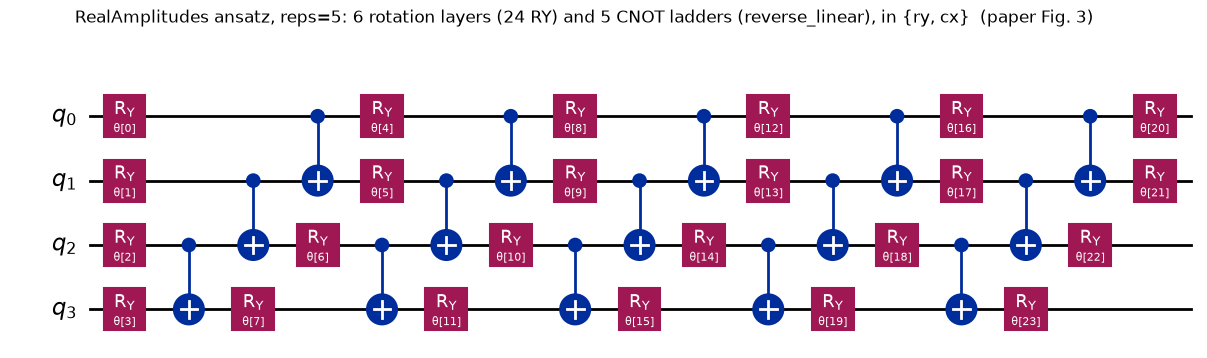

In [13]:
# Figure C: the trainable ansatz in {ry, cx}: this exact gate list is what the fast simulator of Section 3 applies (paper Fig. 3)
fig = ans_flat.draw("mpl", fold=24, style="iqp")
fig.suptitle("RealAmplitudes ansatz, reps=5: 6 rotation layers (24 RY) and 5 CNOT ladders (reverse_linear), in {ry, cx}  (paper Fig. 3)", y=1.03)
display(fig); plt.close(fig)

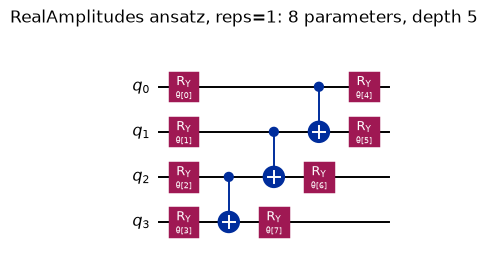

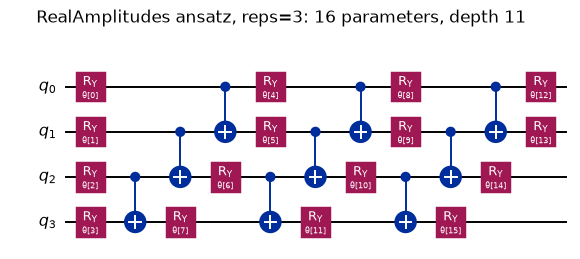

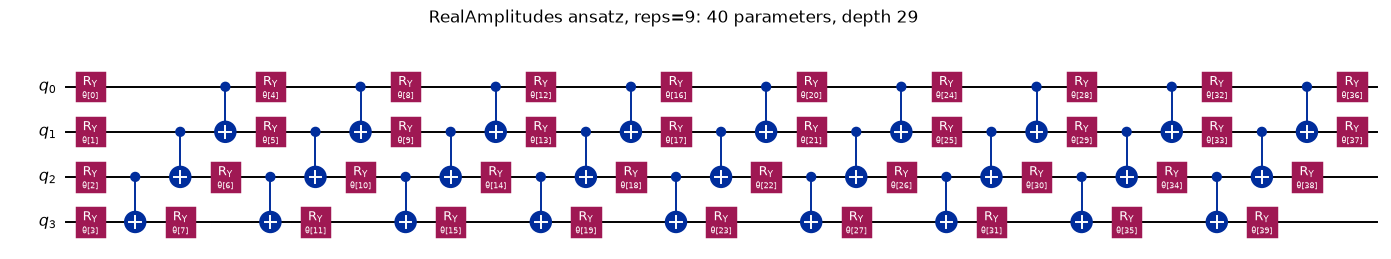

{1: (8, 5), 3: (16, 11), 5: (24, 17), 9: (40, 29)}  (reps -> (parameters, depth))


In [14]:
# Figures D: the other ansatz depths used in the ablation of Section 9 (same feature map; reps=5 is the figure above)
depth_ansatze = {r: real_amplitudes(N_QUBITS, reps=r) for r in DEPTH_REPS}
for r, a in depth_ansatze.items():
    if r == REPS:
        continue
    flat = transpile(a, basis_gates=["ry", "cx"], optimization_level=0)
    fig = flat.draw("mpl", fold=30, style="iqp", scale=0.7)
    fig.suptitle(f"RealAmplitudes ansatz, reps={r}: {a.num_parameters} parameters, depth {flat.depth()}", y=1.04)
    display(fig); plt.close(fig)
print({r: (a.num_parameters, transpile(a, basis_gates=['ry', 'cx'], optimization_level=0).depth()) for r, a in depth_ansatze.items()},
      " (reps -> (parameters, depth))")

## 3. A fast exact simulator for this circuit (and a test that it equals the real Qiskit `VQC`)

Training the real Qiskit `VQC` on 20,155 records costs one circuit execution per record and per loss evaluation; the authors report hours
(156 minutes for 200 COBYLA iterations in their notebooks). Because this circuit is a fixed state preparation followed by a *real*
4-qubit unitary, the output state for every record is simply `U(theta) x`, so the whole training set can be pushed through one 16 x 16 matrix.

The simulator below (a) reads the gate list from the Qiskit ansatz drawn above (24 RY and 15 CNOT), (b) builds `U(theta)` with plain
numpy, (c) applies the sampler's read-out map and (d) draws the same 1024-shot sampling noise as `StatevectorSampler` (for the two-outcome parity
read-out the number of "class 1" shots of a record is Binomial(1024, p); for more classes a multinomial). It optimises with the same
`COBYLA` / `SPSA` classes and the same `CrossEntropyLoss` object as `VQC`, starting from the same default initial point.

The read-out map: the `VQC` class defaults to `interpret(k) = k % num_classes_default` where the default is 2, so a measured integer `k`
is assigned to class `k % 2`, i.e. **the value of qubit 0 alone** (the least significant bit); with `output_shape=K` it would be `k % K`.

In [15]:
def ansatz_gate_list(a):
    # (name, qubit..., parameter index) list of the ansatz in {ry, cx}: the gate list drawn above.
    flat = transpile(a, basis_gates=["ry", "cx"], optimization_level=0)
    pidx = {p: i for i, p in enumerate(a.parameters)}
    gl = []
    for inst in flat.data:
        name, q = inst.operation.name, [flat.find_bit(b).index for b in inst.qubits]
        if name == "ry":
            gl.append(("ry", q[0], pidx[inst.operation.params[0]]))
        elif name == "cx":
            gl.append(("cx", q[0], q[1]))
        else:
            raise ValueError(name)
    return gl

def unitary(theta, gates, n=N_QUBITS):
    # Real 2^n x 2^n matrix of the ansatz; basis index = integer value of the measured bitstring (qubit 0 = least significant bit).
    N = 2 ** n
    T = np.eye(N).reshape([2] * n + [N])                  # axes: q_{n-1}, ..., q_0, column
    for g in gates:
        if g[0] == "ry":
            ax = n - 1 - g[1]; t = theta[g[2]]; c, s = np.cos(t / 2), np.sin(t / 2)
            a0, a1 = np.take(T, 0, axis=ax), np.take(T, 1, axis=ax)
            T = np.stack([c * a0 - s * a1, s * a0 + c * a1], axis=ax)
        else:
            ac, at = n - 1 - g[1], n - 1 - g[2]
            idx = [slice(None)] * (n + 1); idx[ac] = 1
            T = T.copy(); sub = T[tuple(idx)]
            T[tuple(idx)] = np.flip(sub, axis=at if at < ac else at - 1)
    return T.reshape(N, N)

GATES = ansatz_gate_list(ansatz)
print(f"gate list: {sum(g[0]=='ry' for g in GATES)} RY + {sum(g[0]=='cx' for g in GATES)} CX ; CX pairs of repetition 1: {[g[1:] for g in GATES if g[0]=='cx'][:3]}")

# --- test 1: the numpy unitary equals Qiskit's operator for random parameters
r_ = np.random.default_rng(0)
for _ in range(3):
    th = r_.uniform(0, 2 * np.pi, ansatz.num_parameters)
    assert np.allclose(unitary(th, GATES), Operator(ansatz.assign_parameters(th)).data, atol=1e-12)
# --- test 2: the amplitude loader writes the (normalised) record into the amplitudes, in the same basis ordering
x = P["Xte"][5]
assert np.allclose(Statevector(fm.assign_parameters(dict(zip(fm.parameters, x)))).data, x, atol=1e-12)
print("tests 1-2 passed: numpy unitary == Qiskit Operator, loader state == record amplitudes")

gate list: 24 RY + 15 CX ; CX pairs of repetition 1: [(2, 3), (1, 2), (0, 1)]
tests 1-2 passed: numpy unitary == Qiskit Operator, loader state == record amplitudes


In [16]:
class FastAmplitudeVQC:
    # Exact, vectorised equivalent of qiskit_machine_learning.VQC(raw_feature_vector, real_amplitudes) with 1024-shot sampling noise.
    def __init__(self, gates, n_classes=2, decode="parity", shots=SHOTS, n_qubits=N_QUBITS):
        self.gates, self.K, self.shots, self.dim = gates, n_classes, shots, 2 ** n_qubits
        mod = 2 if decode == "parity" else n_classes        # VQC default: k % 2 ; with output_shape=K and its own interpret: k % K
        self.M = np.zeros((self.dim, n_classes)); self.M[np.arange(self.dim), np.arange(self.dim) % mod] = 1.0
        self.reachable = int(np.count_nonzero(self.M.sum(axis=0)))
        self.loss = CrossEntropyLoss()

    def exact_probs(self, theta, X):
        return ((X @ unitary(theta, self.gates).T) ** 2) @ self.M

    def sampled_probs(self, theta, X, rng):
        p = np.clip(self.exact_probs(theta, X), 0, None); p /= p.sum(axis=1, keepdims=True)
        return rng.multinomial(self.shots, p) / self.shots

    def fit(self, X, y, optimizer, x0, rng):
        Y = np.eye(self.K)[y]; hist = []
        def objective(theta):
            v = float(np.sum(self.loss(self.sampled_probs(theta, X, rng), Y)) / len(X)); hist.append(v); return v
        t0 = time.time(); res = optimizer.minimize(objective, x0)
        self.theta = res.x
        return dict(theta=res.x, fun=float(res.fun), nfev=int(res.nfev), hist=np.array(hist), seconds=time.time() - t0)

    def predict(self, X, theta=None, rng=None):
        theta = self.theta if theta is None else theta
        p = self.exact_probs(theta, X) if rng is None else self.sampled_probs(theta, X, rng)
        return p.argmax(axis=1)

def make_optimizer(name, maxiter):
    return {"COBYLA": COBYLA, "SPSA": SPSA}[name](maxiter=maxiter)

def init_point(seed, n_params=24):
    algorithm_globals.random_seed = seed                      # the VQC default: uniform [0, 1)
    return algorithm_globals.random.random(n_params)

In [17]:
# --- test 3: the fast simulator reproduces the class probabilities of the real Qiskit VQC (forward pass of its SamplerQNN)
th = init_point(123); fast = FastAmplitudeVQC(GATES, 2)
X8 = P["Xte"][:12]
qnn_out = vqc_demo.neural_network.forward(X8, th)                         # shape (12, 2): 1024-shot estimates from StatevectorSampler
p_exact = fast.exact_probs(th, X8)
sigma = np.sqrt(np.clip(p_exact * (1 - p_exact), 1e-4, None) / SHOTS)
z = np.abs(qnn_out - p_exact) / sigma
# exact state-vector check of the full executed circuit for three records (no sampling at all)
for i in range(3):
    bound = exec_circ.assign_parameters({**dict(zip(fm.parameters, X8[i])), **dict(zip(ansatz.parameters, th))})
    probs16 = Statevector(bound).probabilities()
    assert np.allclose(probs16, ((unitary(th, GATES) @ X8[i]) ** 2), atol=1e-12)
print("exact 16-outcome distribution of vqc.circuit == |U x|^2 for 3 records: OK")
print(f"largest deviation of the 1024-shot QNN output from the exact probability: {z.max():.2f} sigma over {z.size} values (expected < 4)")
assert z.max() < 4.5

exact 16-outcome distribution of vqc.circuit == |U x|^2 for 3 records: OK
largest deviation of the 1024-shot QNN output from the exact probability: 1.58 sigma over 24 values (expected < 4)


## 4. The real Qiskit `VQC` on a subset, side by side with the fast simulator

Before trusting the fast simulator for the paper-sized runs, train the actual Qiskit `VQC` (the authors' class, `StatevectorSampler`, 1024 shots)
and the fast simulator on the same random subset of the training data, from the same initial point, with the same optimiser. The two cannot give
identical numbers (the shot noise is drawn from different random streams), but they must land in the same place.

In [18]:
sub = np.random.default_rng(SEED)
idx_tr = sub.choice(len(P["Xtr"]), QK_N_TRAIN, replace=False)       # CHOICE: random subset with the natural class mix
idx_te = sub.choice(len(P["Xte"]), QK_N_TEST, replace=False)
Xs, ys, Xt, yt = P["Xtr"][idx_tr], P["ytr"][idx_tr], P["Xte"][idx_te], P["yte"][idx_te]
print(f"subset: {len(Xs)} training records, {len(Xt)} test records, COBYLA/SPSA maxiter = {QK_MAXITER}")

rows = []
for opt in ["COBYLA", "SPSA"]:
    x0 = init_point(SEED)
    # --- the real Qiskit VQC
    vqc = VQC(feature_map=fm, ansatz=ansatz, optimizer=make_optimizer(opt, QK_MAXITER),
              sampler=StatevectorSampler(default_shots=SHOTS, seed=SEED), initial_point=x0.copy())
    t0 = time.time(); vqc.fit(Xs, ys); t_q = time.time() - t0
    pred = np.asarray(vqc.predict(Xt)); pred = pred.argmax(axis=1) if pred.ndim > 1 else pred
    rows.append([opt, "Qiskit VQC (StatevectorSampler, 1024 shots)", float(vqc.fit_result.fun), (pred == yt).mean(), t_q])
    # --- the fast simulator
    fast = FastAmplitudeVQC(GATES, 2)
    r = fast.fit(Xs, ys, make_optimizer(opt, QK_MAXITER), x0.copy(), np.random.default_rng(SEED))
    pf = fast.predict(Xt, rng=np.random.default_rng(SEED + 1))
    rows.append([opt, "fast exact simulator (same shot noise law)", r["fun"], (pf == yt).mean(), r["seconds"]])
qk = pd.DataFrame(rows, columns=["optimizer", "simulator", "final training loss", "test accuracy", "seconds"])
display(qk.round(4))
for opt in ["COBYLA", "SPSA"]:
    a, b = qk[qk.optimizer == opt]["final training loss"].to_numpy()
    print(f"{opt}: final losses differ by {abs(a-b):.3f} (shot noise of one evaluation on {len(Xs)} records is about "
          f"{np.sqrt(0.25/SHOTS/len(Xs)):.3f}; the optimisation paths diverge once the noise differs)")
speedup = qk[qk.simulator.str.startswith("Qiskit")]["seconds"].sum() / qk[qk.simulator.str.startswith("fast")]["seconds"].sum()
print(f"fast simulator is about {speedup:.0f}x faster on this subset")

subset: 150 training records, 500 test records, COBYLA/SPSA maxiter = 50


,optimizer,simulator,final training loss,test accuracy,seconds
0,COBYLA,"Qiskit VQC (StatevectorSampler, 1024 shots)",0.5561,0.842,227.3355
1,COBYLA,fast exact simulator (same shot noise law),0.5763,0.854,0.5123
2,SPSA,"Qiskit VQC (StatevectorSampler, 1024 shots)",0.5461,0.890,1258.3145
3,SPSA,fast exact simulator (same shot noise law),0.5611,0.824,0.8913


COBYLA: final losses differ by 0.020 (shot noise of one evaluation on 150 records is about 0.001; the optimisation paths diverge once the noise differs)
SPSA: final losses differ by 0.015 (shot noise of one evaluation on 150 records is about 0.001; the optimisation paths diverge once the noise differs)
fast simulator is about 1058x faster on this subset


## 5. The binary experiment at the paper's scale (Section 7.1, Table 2)

20,155 training records, 500 COBYLA evaluations and 500 SPSA iterations, cross-entropy loss, the 24 parameters started from the Qiskit
default (uniform [0, 1)). The paper shows one "representative run"; here every run seed gives a different initial point and different shot noise,
so the spread of the 88 % is visible. (Note: COBYLA may stop before 500 evaluations if it converges.)

In [19]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    return dict(acc=accuracy_score(y, p), p0=pr[0], p1=pr[1], r0=rc[0], r1=rc[1], f0=f1[0], f1=f1[1],
                cm=confusion_matrix(y, p, labels=[0, 1]))

def run_binary(seed, opt, X, y, Xe, ye, maxiter=MAXITER, a=None, gates=None):
    a = ansatz if a is None else a; gates = GATES if gates is None else gates
    model = FastAmplitudeVQC(gates, 2)
    x0 = init_point(seed, a.num_parameters)
    r = model.fit(X, y, make_optimizer(opt, maxiter), x0, np.random.default_rng(seed))
    pe = model.predict(Xe, rng=np.random.default_rng(seed + 1000))
    train_acc = (model.predict(X) == y).mean()
    m = metrics(ye, pe)
    return dict(seed=seed, optimizer=opt, train_acc=train_acc, test_acc=m["acc"], final_loss=r["fun"], nfev=r["nfev"],
                seconds=r["seconds"], theta=r["theta"], hist=r["hist"], **{k: m[k] for k in ("p0", "p1", "r0", "r1", "f0", "f1", "cm")})

RUNS = []
for seed in RUN_SEEDS:
    for opt in ["COBYLA", "SPSA"]:
        RUNS.append(run_binary(seed, opt, P["Xtr"], P["ytr"], P["Xte"], P["yte"]))
        r = RUNS[-1]
        print(f"seed {seed} {opt:6s}: train acc {r['train_acc']:.4f} | test acc {r['test_acc']:.4f} | loss {r['final_loss']:.4f} | "
              f"evaluations {r['nfev']:4d} | {r['seconds']:.0f} s")

runs_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("theta", "hist", "cm")} for r in RUNS])
agg = runs_df.groupby("optimizer").agg(["mean", "std"]).drop(columns="seed")
display(agg[["train_acc", "test_acc", "p0", "p1", "r0", "r1", "f0", "f1", "final_loss", "nfev", "seconds"]].round(4))

seed 42 COBYLA: train acc 0.8798 | test acc 0.8821 | loss 0.5336 | evaluations  328 | 16 s


seed 42 SPSA  : train acc 0.8808 | test acc 0.8759 | loss 0.5388 | evaluations 1000 | 34 s


seed 43 COBYLA: train acc 0.8862 | test acc 0.8847 | loss 0.5161 | evaluations  400 | 16 s


seed 43 SPSA  : train acc 0.8631 | test acc 0.8622 | loss 0.5487 | evaluations 1000 | 36 s


seed 44 COBYLA: train acc 0.8698 | test acc 0.8708 | loss 0.5741 | evaluations  281 | 12 s


...

seed 45 COBYLA: train acc 0.8930 | test acc 0.8908 | loss 0.5241 | evaluations  406 | 17 s


seed 45 SPSA  : train acc 0.8806 | test acc 0.8785 | loss 0.5455 | evaluations 1000 | 34 s


seed 46 COBYLA: train acc 0.8725 | test acc 0.8680 | loss 0.5487 | evaluations  386 | 18 s


seed 46 SPSA  : train acc 0.8775 | test acc 0.8777 | loss 0.5457 | evaluations 1000 | 35 s


train_acc         test_acc              p0              p1              r0              r1              f0              f1         final_loss            nfev           seconds        
               mean     std     mean     std    mean     std    mean     std    mean     std    mean     std    mean     std    mean     std       mean     std    mean      std     mean     std
optimizer                                                                                                                                                                                        
COBYLA       0.8803  0.0096   0.8793  0.0096  0.8954  0.0133  0.8619  0.0129  0.8765  0.0134  0.8824  0.0168  0.8858  0.0091  0.8719  0.0104     0.5393  0.0229   360.2  53.9833  15.8118  2.2525
SPSA         0.8724  0.0101   0.8712  0.0085  0.8811  0.0103  0.8608  0.0213  0.8775  0.0231  0.8640  0.0157  0.8791  0.0095  0.8621  0.0076     0.5478  0.0077  1000.0   0.0000  35.0590  0.8324

In [20]:
# Table 2 of the paper, recomputed for the first run seed (SEED) for both optimisers
for opt in ["COBYLA", "SPSA"]:
    r = next(x for x in RUNS if x["seed"] == SEED and x["optimizer"] == opt)
    print(f"=== {opt}, seed {SEED}, 5,037 held-out records  (paper Table 2: accuracy 0.88; P 0.90/0.86; R 0.87/0.89; F1 0.89/0.88) ===")
    print(pd.DataFrame({"Normal (0)": [r["p0"], r["r0"], r["f0"]], "Attack (1)": [r["p1"], r["r1"], r["f1"]]},
                       index=["precision", "recall", "F1"]).round(2).assign(accuracy=["", "", round(r["test_acc"], 2)]).to_string())
    print()

=== COBYLA, seed 42, 5,037 held-out records  (paper Table 2: accuracy 0.88; P 0.90/0.86; R 0.87/0.89; F1 0.89/0.88) ===


           Normal (0)  Attack (1) accuracy
precision        0.88        0.88         
recall           0.90        0.87         
F1               0.89        0.87     0.88

=== SPSA, seed 42, 5,037 held-out records  (paper Table 2: accuracy 0.88; P 0.90/0.86; R 0.87/0.89; F1 0.89/0.88) ===
           Normal (0)  Attack (1) accuracy
precision        0.87        0.88         
recall           0.90        0.85         
F1               0.89        0.86     0.88



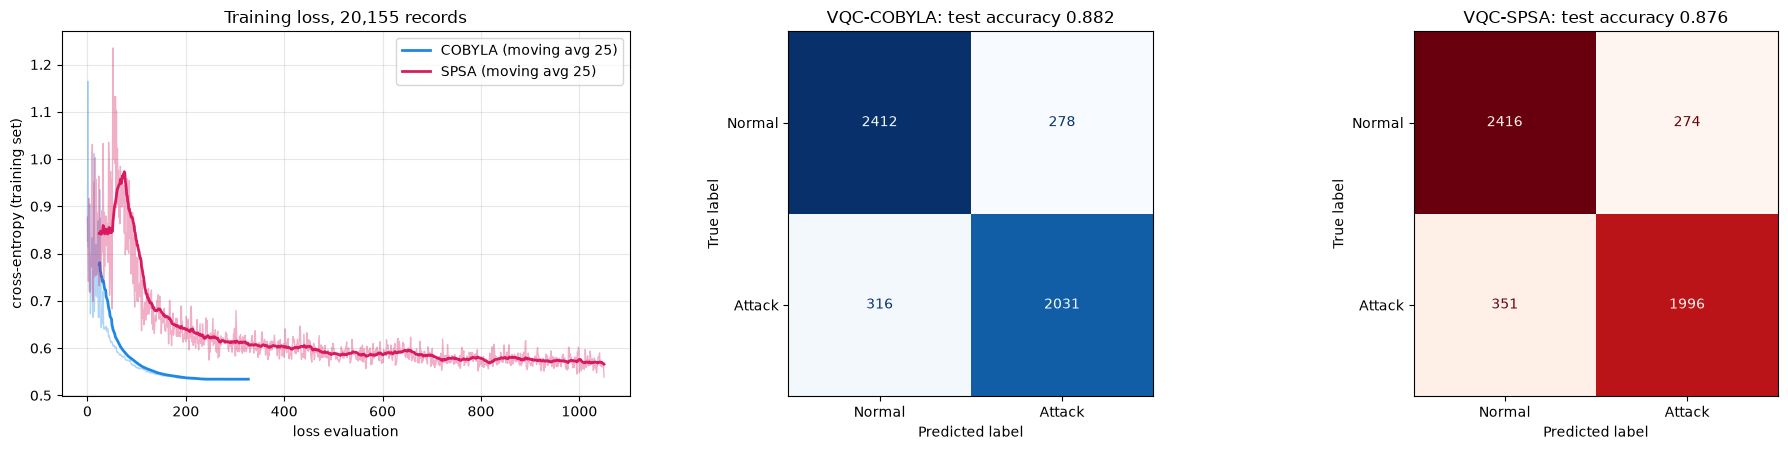

In [21]:
# Loss curves (cross-entropy per loss evaluation, seed = SEED) and confusion matrices (attack = positive class)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
for opt, col in [("COBYLA", "#1E88E5"), ("SPSA", "#D81B60")]:
    r = next(x for x in RUNS if x["seed"] == SEED and x["optimizer"] == opt)
    h = r["hist"]; axes[0].plot(h, color=col, alpha=0.35, lw=1)
    if len(h) > 25:
        axes[0].plot(range(24, len(h)), np.convolve(h, np.ones(25) / 25, mode="valid"), color=col, lw=2, label=f"{opt} (moving avg 25)")
axes[0].set_xlabel("loss evaluation"); axes[0].set_ylabel("cross-entropy (training set)"); axes[0].set_title("Training loss, 20,155 records"); axes[0].legend(); axes[0].grid(alpha=.3)
for ax, opt, cmap in [(axes[1], "COBYLA", "Blues"), (axes[2], "SPSA", "Reds")]:
    r = next(x for x in RUNS if x["seed"] == SEED and x["optimizer"] == opt)
    ConfusionMatrixDisplay(r["cm"], display_labels=["Normal", "Attack"]).plot(ax=ax, cmap=cmap, values_format="d", colorbar=False)
    ax.set_title(f"VQC-{opt}: test accuracy {r['test_acc']:.3f}")
plt.tight_layout(); plt.show()

## 6. Classical baselines on exactly the same inputs (Section 7.3, Fig. 4)

The paper compares the VQC with Logistic Regression (17 parameters, "92 %") and with a "Tiny MLP" whose single hidden layer has 4 nodes
(16 x 4 + 4 + 4 + 1 = 73 parameters, ReLU, Adam, 1000 epochs, "97 %"). All models below receive the identical 16 L2-normalised numbers that go
into the quantum circuit; the last rows show what changes when the L2 step is dropped or when all 42 columns are used.

In [22]:
def fit_eval(name, model, Xa, Xb, inputs):
    t0 = time.time(); model.fit(Xa, P["ytr"]); p = model.predict(Xb); m = metrics(P["yte"], p)
    return dict(model=name, inputs=inputs, test_acc=m["acc"], f1_attack=m["f1"], seconds=time.time() - t0, cm=m["cm"], obj=model)

BASE = []
SAME = "PCA-16 + L2 (same as VQC)"
BASE.append(fit_eval("LogisticRegression (17 params)", LogisticRegression(max_iter=1000, random_state=SEED), P["Xtr"], P["Xte"], SAME))
mlp_runs = []
for s in RUN_SEEDS:
    mlp_runs.append(fit_eval(f"Tiny MLP 4 nodes (seed {s})", MLPClassifier(hidden_layer_sizes=(4,), activation="relu", solver="adam",
                                                                           max_iter=1000, random_state=s), P["Xtr"], P["Xte"], SAME))
BASE.append(mlp_runs[0])
n_par = sum(c.size for c in mlp_runs[0]["obj"].coefs_) + sum(i.size for i in mlp_runs[0]["obj"].intercepts_)
print(f"Tiny MLP parameters: {n_par} (paper: 73)")
BASE.append(fit_eval("SVC rbf (C=1)", SVC(kernel="rbf", C=1.0, random_state=SEED), P["Xtr"], P["Xte"], SAME))
BASE.append(fit_eval("RandomForest (200 trees)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1), P["Xtr"], P["Xte"], SAME))
BASE.append(fit_eval("LogisticRegression", LogisticRegression(max_iter=1000, random_state=SEED), P["Xtr_pca"], P["Xte_pca"], "PCA-16, no L2"))
BASE.append(fit_eval("Tiny MLP 4 nodes", MLPClassifier(hidden_layer_sizes=(4,), max_iter=1000, random_state=SEED), P["Xtr_pca"], P["Xte_pca"], "PCA-16, no L2"))
BASE.append(fit_eval("RandomForest (200 trees)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1), P["Xtr_s"], P["Xte_s"], "all 42 scaled columns"))
base_df = pd.DataFrame([{k: v for k, v in b.items() if k not in ("cm", "obj")} for b in BASE])
display(base_df.round(4))
mlp_accs = np.array([m["test_acc"] for m in mlp_runs])
print(f"Tiny MLP over {len(mlp_runs)} seeds: {mlp_accs.mean():.4f} +- {mlp_accs.std(ddof=1) if len(mlp_accs) > 1 else 0:.4f}")

Tiny MLP parameters: 73 (paper: 73)


,model,inputs,test_acc,f1_attack,seconds
0,LogisticRegression (17 params),PCA-16 + L2 (same as VQC),0.9244,0.9211,0.2509
1,Tiny MLP 4 nodes (seed 42),PCA-16 + L2 (same as VQC),0.9692,0.9670,46.9374
2,SVC rbf (C=1),PCA-16 + L2 (same as VQC),0.9776,0.9758,19.6617
3,RandomForest (200 trees),PCA-16 + L2 (same as VQC),0.9897,0.9889,11.0354
4,LogisticRegression,"PCA-16, no L2",0.9412,0.9370,0.3342
5,Tiny MLP 4 nodes,"PCA-16, no L2",0.9690,0.9666,37.5943
6,RandomForest (200 trees),all 42 scaled columns,0.9976,0.9974,3.3868


Tiny MLP over 5 seeds: 0.9696 +- 0.0024


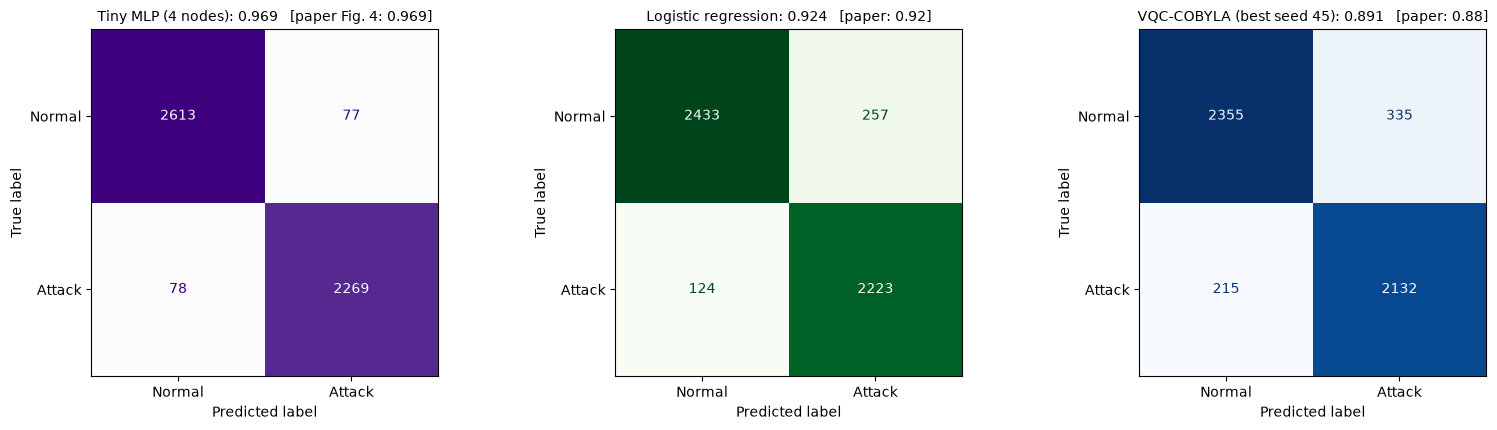

paper Fig. 4 counts : TN 2613, FP 77, FN 78, TP 2269
this notebook (MLP) : TN 2613, FP 77, FN 78, TP 2269


In [23]:
# Paper Fig. 4: confusion matrix of the Tiny MLP (paper: [[2613, 77], [78, 2269]]) next to the logistic regression and the best VQC run
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
mlp0 = BASE[1]; lr0 = BASE[0]; best = max([r for r in RUNS if r["optimizer"] == "COBYLA"], key=lambda r: r["test_acc"])
for ax, cm, title, cmap in [(axes[0], mlp0["cm"], f"Tiny MLP (4 nodes): {mlp0['test_acc']:.3f}   [paper Fig. 4: 0.969]", "Purples"),
                            (axes[1], lr0["cm"], f"Logistic regression: {lr0['test_acc']:.3f}   [paper: 0.92]", "Greens"),
                            (axes[2], best["cm"], f"VQC-COBYLA (best seed {best['seed']}): {best['test_acc']:.3f}   [paper: 0.88]", "Blues")]:
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"]).plot(ax=ax, cmap=cmap, values_format="d", colorbar=False); ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()
print("paper Fig. 4 counts : TN 2613, FP 77, FN 78, TP 2269")
print("this notebook (MLP) : TN %d, FP %d, FN %d, TP %d" % tuple(mlp0["cm"].ravel()))

## 7. Sensitivity: what if the target encoding used the real attack indicator?

The paper *describes* an attack-probability encoding; the released code ends up with a constant. The cell below runs the other variant through the
whole binary pipeline (one run seed per optimiser) to see whether the headline numbers depend on this.

In [24]:
ALT_MODE = "as_described" if TARGET_ENCODING_MODE == "released_code" else "released_code"
PA = build_features(train_set, test_set, ALT_MODE)
print(f"alternative mode '{ALT_MODE}': first encoded rows\n{PA['enc_train_example']}\nPCA-16 explained variance {PA['ev']:.2%} (mode '{TARGET_ENCODING_MODE}': {P['ev']:.2%})")
sens = []
for opt in ["COBYLA", "SPSA"]:
    r = run_binary(SEED, opt, PA["Xtr"], P["ytr"], PA["Xte"], P["yte"])
    sens.append(dict(model=f"VQC-{opt}", test_acc=r["test_acc"], f1_attack=r["f1"]))
for name, mdl in [("LogisticRegression", LogisticRegression(max_iter=1000, random_state=SEED)),
                  ("Tiny MLP 4 nodes", MLPClassifier(hidden_layer_sizes=(4,), max_iter=1000, random_state=SEED)),
                  ("RandomForest (200 trees)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]:
    mdl.fit(PA["Xtr"], P["ytr"]); m = metrics(P["yte"], mdl.predict(PA["Xte"]))
    sens.append(dict(model=name, test_acc=m["acc"], f1_attack=m["f1"]))
main_acc = {"VQC-COBYLA": next(r["test_acc"] for r in RUNS if r["seed"] == SEED and r["optimizer"] == "COBYLA"),
            "VQC-SPSA": next(r["test_acc"] for r in RUNS if r["seed"] == SEED and r["optimizer"] == "SPSA"),
            "LogisticRegression": BASE[0]["test_acc"], "Tiny MLP 4 nodes": BASE[1]["test_acc"], "RandomForest (200 trees)": BASE[3]["test_acc"]}
sens_df = pd.DataFrame(sens)
sens_df.insert(1, f"test acc, mode '{TARGET_ENCODING_MODE}'", [main_acc[m] for m in sens_df.model])
sens_df = sens_df.rename(columns={"test_acc": f"test acc, mode '{ALT_MODE}'"})
display(sens_df.round(4))

alternative mode 'as_described': first encoded rows
[[0.48  0.057 0.155 0.012]
 [0.481 0.056 0.154 0.149]
 [0.167 0.955 0.155 0.012]]
PCA-16 explained variance 85.36% (mode 'released_code': 86.78%)


,model,"test acc, mode 'released_code'","test acc, mode 'as_described'",f1_attack
0,VQC-COBYLA,0.8821,0.8702,0.8609
1,VQC-SPSA,0.8759,0.8708,0.8564
2,LogisticRegression,0.9244,0.9539,0.9511
3,Tiny MLP 4 nodes,0.9692,0.9807,0.9792
4,RandomForest (200 trees),0.9897,0.9954,0.9951


## 8. Multiclass experiments (Section 8)

Two stress tests, both with the same circuit. The first thing to settle is *what the circuit can say*: the `VQC` class turns the measured
integer `k` into the class `k % 2` unless `output_shape` is passed. With 4 or 22 one-hot target columns but no `output_shape`, the network output has
4 or 22 entries, yet only entries 0 and 1 can ever receive probability. The cell below checks this on the real Qiskit `VQC` (a 2-iteration fit on a handful of records is
enough to see the output shape and which columns are non-zero).

In [25]:
def decoding_diagnostic(K, **vqc_kwargs):
    # fit the real Qiskit VQC for 2 COBYLA iterations on 3*K records of K classes, then look at the network output
    r_ = np.random.default_rng(0); y_ = np.repeat(np.arange(K), 3); X_ = normalize(r_.normal(size=(len(y_), FEATURE_DIM)))
    v = VQC(feature_map=fm, ansatz=ansatz, optimizer=COBYLA(maxiter=2), sampler=StatevectorSampler(default_shots=256, seed=0), **vqc_kwargs)
    v.fit(X_, y_)
    out = v.neural_network.forward(X_[:20], v.fit_result.x)
    cols = np.where(np.abs(out).sum(axis=0) > 0)[0]
    return out.shape[1], [int(c) for c in cols]

for K in (4, 22):
    n_out, cols = decoding_diagnostic(K)
    print(f"{K:2d} classes, default VQC (no output_shape): network outputs {n_out} entries; entries that ever get probability: {list(cols)}")
    n_out, cols = decoding_diagnostic(K, output_shape=K)
    print(f"{K:2d} classes, VQC(output_shape={K}) (interpret = k % {K}): {n_out} entries; entries that ever get probability: {list(cols)}"
          f" -> {len(cols)} of {K} classes reachable from 16 basis states")

 4 classes, default VQC (no output_shape): network outputs 4 entries; entries that ever get probability: [0, 1]


 4 classes, VQC(output_shape=4) (interpret = k % 4): 4 entries; entries that ever get probability: [0, 1, 2, 3] -> 4 of 4 classes reachable from 16 basis states


22 classes, default VQC (no output_shape): network outputs 22 entries; entries that ever get probability: [0, 1]


22 classes, VQC(output_shape=22) (interpret = k % 22): 22 entries; entries that ever get probability: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15] -> 16 of 22 classes reachable from 16 basis states


### 8.1 Imbalanced four-family classifier (Table 3, Fig. 5)

Only attack records are used. The training set is a random draw of the natural class mix (the paper does not give its size; the authors' `SMOTE`
notebook tests on the first 400 attack records of the held-out split, which also matches the 320 + 73 + 7 = 400 in the paper's Fig. 5, so the same 400 are used here).
COBYLA runs 150 iterations. We evaluate two read-outs: the default one (what the paper's numbers come from, since no `output_shape` was passed) and
`output_shape=4`, as the authors later did in `multiclass_4class_fixed.ipynb`.

In [26]:
atk_tr = np.where(P["ytr"] == 1)[0]; atk_te = np.where(P["yte"] == 1)[0]
fam_tr = np.array([FAM_ID[f] for f in P["ytr_family"][atk_tr]]); fam_te = np.array([FAM_ID[f] for f in P["yte_family"][atk_te]])
Xt4, yt4 = P["Xte"][atk_te][:IMB_TEST_N], fam_te[:IMB_TEST_N]
print("attack records in the training split by family:", {n: int(v) for n, v in zip(FAM_NAMES, np.bincount(fam_tr, minlength=4))})
print(f"first {IMB_TEST_N} held-out attack records by family:", {n: int(v) for n, v in zip(FAM_NAMES, np.bincount(yt4, minlength=4))}, "(paper Fig. 5: 320 / 73 / 7 / 0)")

IMB = {}
for decode in ["parity", "mod"]:
    accs = []
    for seed in RUN_SEEDS:
        sel = np.random.default_rng(seed).choice(len(atk_tr), IMB_TRAIN_N, replace=False)          # CHOICE: random 1,000 natural-mix records
        m4 = FastAmplitudeVQC(GATES, 4, decode=decode)
        r = m4.fit(P["Xtr"][atk_tr][sel], fam_tr[sel], make_optimizer("COBYLA", IMB_MAXITER), init_point(seed), np.random.default_rng(seed))
        pred = m4.predict(Xt4, rng=np.random.default_rng(seed + 1000))
        accs.append((pred == yt4).mean())
        if seed == SEED:
            IMB[decode] = dict(pred=pred, rep=classification_report(yt4, pred, labels=[0, 1, 2, 3], target_names=FAM_NAMES, zero_division=0, output_dict=True),
                               cm=confusion_matrix(yt4, pred, labels=[0, 1, 2, 3]), train_n=len(sel), train_mix=np.bincount(fam_tr[sel], minlength=4))
    IMB[decode]["accs"] = np.array(accs)
    print(f"\n--- decode = {decode} ({'default VQC read-out k % 2' if decode == 'parity' else 'output_shape=4, k % 4'}), seed {SEED}, "
          f"training mix {dict((n, int(v)) for n, v in zip(FAM_NAMES, IMB[decode]['train_mix']))} ---")
    print(classification_report(yt4, IMB[decode]["pred"], labels=[0, 1, 2, 3], target_names=FAM_NAMES, zero_division=0, digits=2))
    print(f"accuracy over {len(accs)} seeds: {np.mean(accs):.3f} +- {np.std(accs, ddof=1) if len(accs) > 1 else 0:.3f}")

attack records in the training split by family: {'DoS': 7386, 'Probe': 1832, 'R2L': 168, 'U2R': 10}
first 400 held-out attack records by family: {'DoS': 320, 'Probe': 73, 'R2L': 7, 'U2R': 0} (paper Fig. 5: 320 / 73 / 7 / 0)



--- decode = parity (default VQC read-out k % 2), seed 42, training mix {'DoS': 801, 'Probe': 184, 'R2L': 15, 'U2R': 0} ---
              precision    recall  f1-score   support

         DoS       0.96      0.99      0.98       320
       Probe       0.90      0.86      0.88        73
         R2L       0.00      0.00      0.00         7
         U2R       0.00      0.00      0.00         0

    accuracy                           0.95       400
   macro avg       0.47      0.46      0.46       400
weighted avg       0.93      0.95      0.94       400

accuracy over 5 seeds: 0.936 +- 0.016



--- decode = mod (output_shape=4, k % 4), seed 42, training mix {'DoS': 801, 'Probe': 184, 'R2L': 15, 'U2R': 0} ---
              precision    recall  f1-score   support

         DoS       0.94      1.00      0.97       320
       Probe       1.00      0.51      0.67        73
         R2L       1.00      0.29      0.44         7
         U2R       0.00      0.00      0.00         0

    accuracy                           0.90       400
   macro avg       0.74      0.45      0.52       400
weighted avg       0.95      0.90      0.91       400

accuracy over 5 seeds: 0.869 +- 0.054


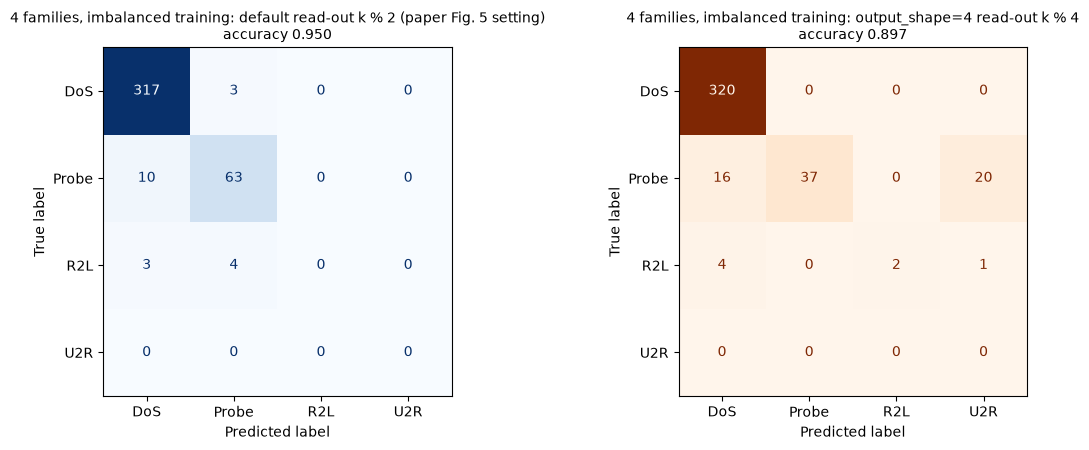

paper Fig. 5 : DoS row [276, 44, 0, 0] ; Probe row [5, 68, 0, 0] ; R2L row [0, 7, 0, 0] (no R2L / U2R prediction at all)


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, decode, ttl, cmap in [(axes[0], "parity", "default read-out k % 2 (paper Fig. 5 setting)", "Blues"),
                              (axes[1], "mod", "output_shape=4 read-out k % 4", "Oranges")]:
    ConfusionMatrixDisplay(IMB[decode]["cm"], display_labels=FAM_NAMES).plot(ax=ax, cmap=cmap, values_format="d", colorbar=False)
    ax.set_title(f"4 families, imbalanced training: {ttl}\naccuracy {IMB[decode]['accs'][0]:.3f}", fontsize=10)
plt.tight_layout(); plt.show()
print("paper Fig. 5 : DoS row [276, 44, 0, 0] ; Probe row [5, 68, 0, 0] ; R2L row [0, 7, 0, 0] (no R2L / U2R prediction at all)")

### 8.2 Balanced 22-label in-sample probe (Section 8.2)

200 training records per label (with replacement for the 20 labels that have fewer; `normal` is one of the 22), COBYLA 150 iterations, and
**evaluation on the very same 4,400 records**, as the paper does. Under the default read-out only entries 0 and 1 of the 22-dimensional output
can carry probability, so the accuracy cannot exceed 2/22 = 9.09 % whatever the circuit learns. The cell also runs the read-out `k % 22`
(which, with only 16 basis states, can reach 16 of the 22 labels) and three classical models on the same 4,400 records to show what the data allow in-sample.

In [28]:
labels_sorted = sorted(df["label"].unique())                         # LabelBinarizer order: 'back' = 0, 'buffer_overflow' = 1, ...
lab_id = {l: i for i, l in enumerate(labels_sorted)}
y22_all = np.array([lab_id[l] for l in P["ytr_label"]])
rb = np.random.default_rng(42)                                       # CHOICE: seed of the oversampling (the paper's random_state=42)
bal_idx = np.concatenate([rb.choice(np.where(y22_all == k)[0], BAL_PER_CLASS, replace=(y22_all == k).sum() < BAL_PER_CLASS) for k in range(22)])
bal_idx = rb.permutation(bal_idx)
Xb, yb = P["Xtr"][bal_idx], y22_all[bal_idx]
print(f"balanced set: {Xb.shape}, {len(np.unique(yb))} labels x {BAL_PER_CLASS}; label 0 = {labels_sorted[0]}, label 1 = {labels_sorted[1]}")

BAL = {}
for decode in ["parity", "mod"]:
    accs, sets = [], []
    for seed in RUN_SEEDS:
        m22 = FastAmplitudeVQC(GATES, 22, decode=decode)
        r = m22.fit(Xb, yb, make_optimizer("COBYLA", BAL_MAXITER), init_point(seed), np.random.default_rng(seed))
        pred = m22.predict(Xb, rng=np.random.default_rng(seed + 1000))
        accs.append((pred == yb).mean()); sets.append(sorted(set(pred.tolist())))
        if seed == SEED:
            BAL[decode] = dict(pred=pred, reach=m22.reachable, loss=r["fun"])
    BAL[decode].update(accs=np.array(accs), predicted_sets=sets)
    print(f"decode={decode:6s}: reachable labels {BAL[decode]['reach']:2d}/22 (bound {BAL[decode]['reach']/22:.2%}) | in-sample accuracy over {len(accs)} seeds: "
          f"{np.mean(accs):.4f} +- {np.std(accs, ddof=1) if len(accs) > 1 else 0:.4f} | labels ever predicted (seed {SEED}): "
          f"{[labels_sorted[k] for k in sets[0]] if len(sets[0]) <= 6 else str(len(sets[0])) + ' labels'}")

pp = BAL["parity"]["pred"]
rep22 = pd.DataFrame(classification_report(yb, pp, labels=list(range(22)), target_names=labels_sorted, zero_division=0, output_dict=True)).T.round(2)
print("\nclassification report of the default read-out (seed %d), rows with any prediction + summary:" % SEED)
display(rep22[(rep22["precision"] > 0) | rep22.index.isin(["accuracy", "macro avg", "weighted avg"])])

balanced set: (4400, 16), 22 labels x 200; label 0 = back, label 1 = buffer_overflow


decode=parity: reachable labels  2/22 (bound 9.09%) | in-sample accuracy over 5 seeds: 0.0905 +- 0.0003 | labels ever predicted (seed 42): ['back', 'buffer_overflow']


decode=mod   : reachable labels 16/22 (bound 72.73%) | in-sample accuracy over 5 seeds: 0.1012 +- 0.0607 | labels ever predicted (seed 42): 16 labels

classification report of the default read-out (seed 42), rows with any prediction + summary:


,precision,recall,f1-score,support
back,0.11,1.00,0.20,200.00
buffer_overflow,0.08,1.00,0.14,200.00
accuracy,0.09,0.09,0.09,0.09
macro avg,0.01,0.09,0.02,4400.00
weighted avg,0.01,0.09,0.02,4400.00


,model,in_sample_acc,distinct_labels_predicted
0,Tiny MLP (4 hidden nodes),0.9464,22
1,Logistic regression,0.8973,22
2,RandomForest (200 trees),1.0000,22
3,"VQC, default read-out (k % 2)",0.0905,2
4,"VQC, read-out k % 22 (16 labels reachable)",0.1012,16


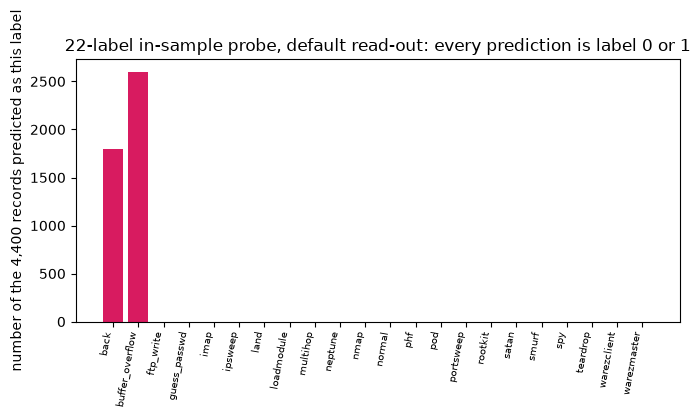

In [29]:
# Classical models on the same 4,400 records, evaluated in-sample like the paper's probe (and on the held-out split for context)
Xte22 = P["Xte"]; yte22 = np.array([lab_id[l] for l in P["yte_label"]])
cl = []
for name, mdl in [("Tiny MLP (4 hidden nodes)", MLPClassifier(hidden_layer_sizes=(4,), max_iter=1000, random_state=SEED)),
                  ("Logistic regression", LogisticRegression(max_iter=2000, random_state=SEED)),
                  ("RandomForest (200 trees)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]:
    mdl.fit(Xb, yb)
    cl.append(dict(model=name, in_sample_acc=(mdl.predict(Xb) == yb).mean(), distinct_labels_predicted=len(set(mdl.predict(Xb).tolist()))))
cl.append(dict(model="VQC, default read-out (k % 2)", in_sample_acc=BAL["parity"]["accs"].mean(), distinct_labels_predicted=len(BAL["parity"]["predicted_sets"][0])))
cl.append(dict(model="VQC, read-out k % 22 (16 labels reachable)", in_sample_acc=BAL["mod"]["accs"].mean(), distinct_labels_predicted=len(BAL["mod"]["predicted_sets"][0])))
display(pd.DataFrame(cl).round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(22), np.bincount(pp, minlength=22), color=["#D81B60" if k < 2 else "#BBBBBB" for k in range(22)])
ax.set_xticks(range(22)); ax.set_xticklabels(labels_sorted, rotation=80, ha="right", fontsize=7)
ax.set_ylabel("number of the 4,400 records predicted as this label"); ax.set_title("22-label in-sample probe, default read-out: every prediction is label 0 or 1")
plt.tight_layout(); plt.show()

## 9. Extension: does depth change the ceiling? (the ablation the paper asks for in Section 9.3)

The paper concludes the 88 % is an encoding limit, but its own limitations section says the ansatz depth was never varied. With the fast simulator
the experiment is cheap: the same amplitude-encoded binary task with `reps` in {1, 3, 5, 9} (8, 16, 24, 40 parameters), COBYLA with the same
500-evaluation budget, same inputs and read-out. (This is not a claim of the paper.)

,reps,params,test_acc,test_acc_std,train_loss,evaluations,seconds
0,1,8,0.8180,0.0044,0.6571,83.6667,3.2484
1,3,16,0.8801,0.0058,0.5483,223.3333,9.5159
2,5,24,0.8792,0.0074,0.5413,336.3333,15.4816
3,9,40,0.8838,0.0055,0.5256,500.0000,24.6090


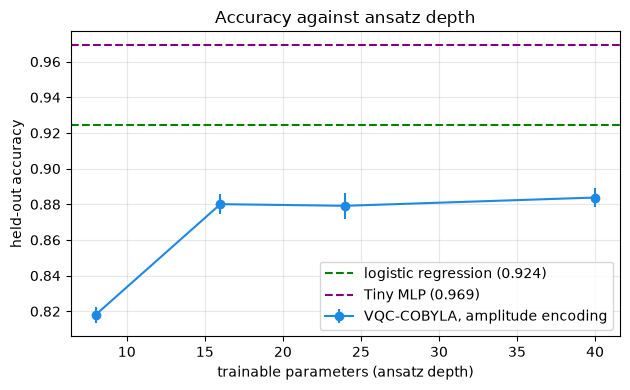

In [30]:
SW = []
for reps in DEPTH_REPS:
    a_ = depth_ansatze[reps]; g_ = ansatz_gate_list(a_)
    for s in [SEED + i for i in range(DEPTH_SEEDS)]:
        r = run_binary(s, "COBYLA", P["Xtr"], P["ytr"], P["Xte"], P["yte"], a=a_, gates=g_)
        SW.append(dict(reps=reps, params=a_.num_parameters, seed=s, test_acc=r["test_acc"], train_loss=r["final_loss"], evaluations=r["nfev"], seconds=r["seconds"]))
sw = pd.DataFrame(SW)
sw_tab = sw.groupby(["reps", "params"]).agg(test_acc=("test_acc", "mean"), test_acc_std=("test_acc", "std"), train_loss=("train_loss", "mean"),
                                            evaluations=("evaluations", "mean"), seconds=("seconds", "mean")).reset_index()
display(sw_tab.round(4))
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.errorbar(sw_tab.params, sw_tab.test_acc, yerr=sw_tab.test_acc_std.fillna(0), fmt="o-", color="#1E88E5", label="VQC-COBYLA, amplitude encoding")
lr_acc = BASE[0]["test_acc"]; mlp_acc = BASE[1]["test_acc"]
ax.axhline(lr_acc, color="green", ls="--", label=f"logistic regression ({lr_acc:.3f})"); ax.axhline(mlp_acc, color="purple", ls="--", label=f"Tiny MLP ({mlp_acc:.3f})")
ax.set_xlabel("trainable parameters (ansatz depth)"); ax.set_ylabel("held-out accuracy"); ax.set_title("Accuracy against ansatz depth"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 10. Extension: the same trained circuit on a noisy IBM fake backend (the "NISQ" of the title)

The paper stresses NISQ hardware but simulates ideally. Here the COBYLA-trained circuit of seed `SEED` classifies held-out records on the noise model of
`FakeLimaV2` (5 qubits, linear coupling; `qiskit_ibm_runtime.fake_provider` + Aer), after transpilation to the device's basis gates. Only the *inference* is
run noisy; nothing is retrained. No IBM account is used. (`IBM_TOKEN` stays empty; real-hardware cells are not included.)

100 held-out records on fake_lima: ideal accuracy 0.900 | noisy accuracy 0.880 | mean |p_noisy - p_ideal| = 0.084 | 10 s
transpiled circuit: depth 90, gates {'rz': 70, 'sx': 62, 'cx': 44, 'reset': 4, 'measure': 4, 'x': 2, 'barrier': 1}


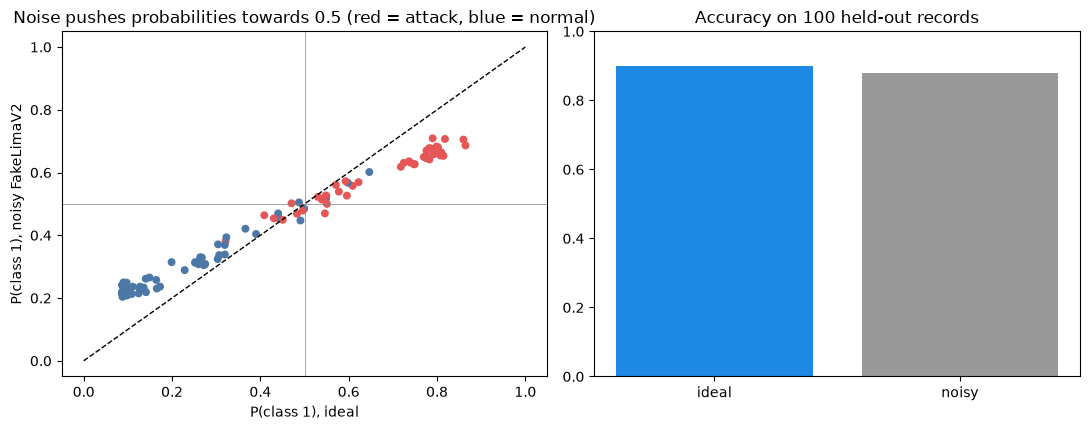

In [31]:
from qiskit_ibm_runtime.fake_provider import FakeLimaV2
from qiskit_aer import AerSimulator

theta_star = next(r for r in RUNS if r["seed"] == SEED and r["optimizer"] == "COBYLA")["theta"]
backend = FakeLimaV2(); sim = AerSimulator.from_backend(backend, seed_simulator=SEED)
Xn, yn = P["Xte"][:NOISY_N], P["yte"][:NOISY_N]
circs = [meas_circ.assign_parameters({**dict(zip(fm.parameters, x)), **dict(zip(ansatz.parameters, theta_star))}) for x in Xn]
t0 = time.time()
tq = transpile(circs, backend, optimization_level=1, seed_transpiler=SEED)
counts = sim.run(tq, shots=SHOTS).result().get_counts()
p1_noisy = np.array([sum(v for k, v in c.items() if k.replace(" ", "")[-1] == "1") / SHOTS for c in counts])      # class 1 <=> measured integer is odd <=> qubit 0 reads 1
p1_ideal = FastAmplitudeVQC(GATES, 2).exact_probs(theta_star, Xn)[:, 1]
acc_noisy, acc_ideal = ((p1_noisy > 0.5) == yn).mean(), ((p1_ideal > 0.5) == yn).mean()
print(f"{NOISY_N} held-out records on {backend.name}: ideal accuracy {acc_ideal:.3f} | noisy accuracy {acc_noisy:.3f} | "
      f"mean |p_noisy - p_ideal| = {np.abs(p1_noisy - p1_ideal).mean():.3f} | {time.time()-t0:.0f} s")
print(f"transpiled circuit: depth {tq[0].depth()}, gates {dict(tq[0].count_ops())}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(p1_ideal, p1_noisy, c=np.where(yn == 1, "#E45756", "#4C78A8"), s=22)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].axhline(.5, color="gray", lw=.5); axes[0].axvline(.5, color="gray", lw=.5)
axes[0].set_xlabel("P(class 1), ideal"); axes[0].set_ylabel("P(class 1), noisy FakeLimaV2"); axes[0].set_title("Noise pushes probabilities towards 0.5 (red = attack, blue = normal)")
axes[1].bar(["ideal", "noisy"], [acc_ideal, acc_noisy], color=["#1E88E5", "#999999"]); axes[1].set_ylim(0, 1); axes[1].set_title(f"Accuracy on {NOISY_N} held-out records")
plt.tight_layout(); plt.show()

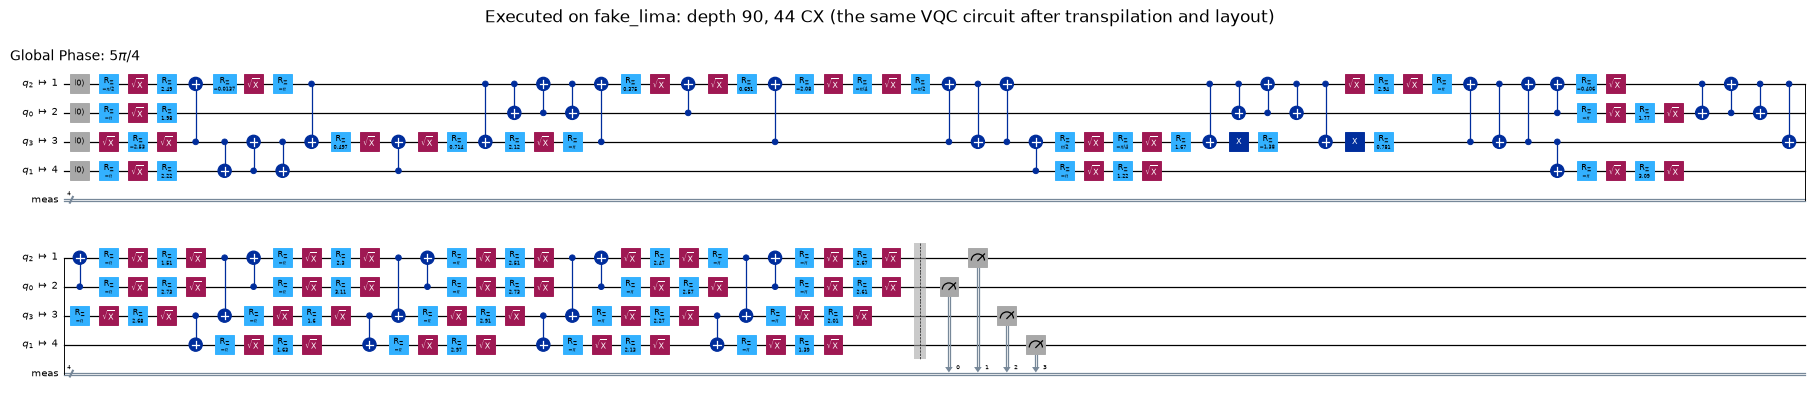

In [32]:
# The circuit that is actually executed on the fake device: record #0 with the trained weights, transpiled to the device basis
fig = tq[0].draw("mpl", fold=60, idle_wires=False, scale=0.45)
fig.suptitle(f"Executed on {backend.name}: depth {tq[0].depth()}, {tq[0].count_ops().get('cx', 0)} CX (the same VQC circuit after transpilation and layout)", y=1.0)
display(fig); plt.close(fig)

## 11. The paper's numbers next to this notebook's

Every claim of the paper that can be tested is listed with the paper's value, the notebook's value and a verdict. Tolerance: 0.02 on accuracies and F1 / precision / recall,
0.005 on the explained variance. "Reproduced" means within tolerance; otherwise "not reached" or "exceeded" with the gap. Values for the VQC are the mean over the run seeds.

In [33]:
def acc_mean(opt): return float(np.mean([r["test_acc"] for r in RUNS if r["optimizer"] == opt]))
def met_mean(opt, key): return float(np.mean([r[key] for r in RUNS if r["optimizer"] == opt]))

ROWS = []
def add(cid, claim, paper, ours, tol=0.02, kind="num"):
    if kind == "exact":
        v = "reproduced" if paper == ours else "not reproduced"
        ROWS.append((cid, claim, str(paper), str(ours), v)); return
    gap = ours - paper
    v = "reproduced" if abs(gap) <= tol else (f"exceeded by {gap:+.3f}" if gap > 0 else f"not reached ({gap:+.3f})")
    ROWS.append((cid, claim, f"{paper:.4f}", f"{ours:.4f}", v))

add("C1", "train / test sizes and singleton count", (20155, 5037, 8), (len(train_set), len(test_set), len(singletons)), kind="exact")
add("C2", "PCA-16 explained variance (mode '%s')" % TARGET_ENCODING_MODE, 0.8678, P["ev"], tol=0.005)
add("C3", "ansatz trainable parameters", 24, ansatz.num_parameters, kind="exact")
add("C4", "VQC-COBYLA accuracy (Table 2)", 0.88, acc_mean("COBYLA"))
add("C4", "VQC-COBYLA precision Normal / Attack", 0.90, met_mean("COBYLA", "p0")); add("C4", "  precision Attack", 0.86, met_mean("COBYLA", "p1"))
add("C4", "VQC-COBYLA recall Normal", 0.87, met_mean("COBYLA", "r0")); add("C4", "  recall Attack", 0.89, met_mean("COBYLA", "r1"))
add("C4", "VQC-COBYLA F1 Normal", 0.89, met_mean("COBYLA", "f0")); add("C4", "  F1 Attack", 0.88, met_mean("COBYLA", "f1"))
add("C5", "VQC-SPSA accuracy (paper: same plateau as COBYLA)", 0.88, acc_mean("SPSA"))
ROWS.append(("C5", "COBYLA and SPSA differ by <= 0.02", "<= 0.02", f"{abs(acc_mean('COBYLA') - acc_mean('SPSA')):.4f}",
             "reproduced" if abs(acc_mean('COBYLA') - acc_mean('SPSA')) <= 0.02 else "not reproduced"))
add("C6", "Logistic regression accuracy, same inputs", 0.92, BASE[0]["test_acc"])
add("C7", "Tiny MLP (4 nodes) accuracy, same inputs", 0.97, BASE[1]["test_acc"])
add("C7", "Tiny MLP parameters", 73, n_par, kind="exact")
add("C8", "4 families, imbalanced, overall accuracy (Table 3: 0.91)", 0.91, IMB["parity"]["accs"].mean())
ROWS.append(("C8", "R2L and U2R recall exactly 0", "0 and 0", f"{IMB['parity']['rep']['R2L']['recall']:.2f} and {IMB['parity']['rep']['U2R']['recall']:.2f}",
             "reproduced" if IMB['parity']['rep']['R2L']['recall'] == 0 and IMB['parity']['rep']['U2R']['recall'] == 0 else "not reproduced"))
add("C9", "22 labels, balanced, in-sample accuracy", 0.09, BAL["parity"]["accs"].mean(), tol=0.02)
ROWS.append(("C9", "only 'back' and 'buffer_overflow' are ever predicted", "2 labels", f"{len(BAL['parity']['predicted_sets'][0])} labels: {[labels_sorted[k] for k in BAL['parity']['predicted_sets'][0]]}",
             "reproduced" if BAL['parity']['predicted_sets'][0] == [0, 1] or set(BAL['parity']['predicted_sets'][0]) <= {0, 1} else "not reproduced"))
ROWS.append(("C10", "the plateau is an encoding limit, not an optimisation artefact", "claimed", "see Section 12", "cannot be checked as stated"))
cmp_df = pd.DataFrame(ROWS, columns=["id", "claim", "paper", "this notebook", "verdict"])
display(cmp_df.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print(cmp_df["verdict"].value_counts().to_string())

id,claim,paper,this notebook,verdict
C1,train / test sizes and singleton count,"(20155, 5037, 8)","(20155, 5037, 8)",reproduced
C2,PCA-16 explained variance (mode 'released_code'),0.8678,0.8678,reproduced
C3,ansatz trainable parameters,24,24,reproduced
C4,VQC-COBYLA accuracy (Table 2),0.8800,0.8793,reproduced
C4,VQC-COBYLA precision Normal / Attack,0.9000,0.8954,reproduced
C4,precision Attack,0.8600,0.8619,reproduced
C4,VQC-COBYLA recall Normal,0.8700,0.8765,reproduced
C4,recall Attack,0.8900,0.8824,reproduced
C4,VQC-COBYLA F1 Normal,0.8900,0.8858,reproduced
C4,F1 Attack,0.8800,0.8719,reproduced


verdict
reproduced                     18
exceeded by +0.026              1
cannot be checked as stated     1


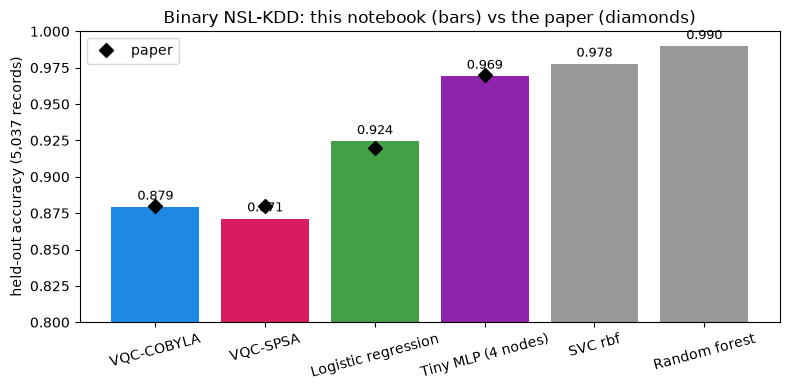

In [34]:
# One-picture summary: held-out accuracy of every model on the binary task (bars) with the paper's values (diamonds)
rows = [("VQC-COBYLA", acc_mean("COBYLA"), 0.88), ("VQC-SPSA", acc_mean("SPSA"), 0.88), ("Logistic regression", BASE[0]["test_acc"], 0.92),
        ("Tiny MLP (4 nodes)", BASE[1]["test_acc"], 0.97), ("SVC rbf", BASE[2]["test_acc"], None), ("Random forest", BASE[3]["test_acc"], None)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([r[0] for r in rows], [r[1] for r in rows], color=["#1E88E5", "#D81B60", "#43A047", "#8E24AA", "#999999", "#999999"])
for i, r in enumerate(rows):
    ax.text(i, r[1] + 0.005, f"{r[1]:.3f}", ha="center", fontsize=9)
    if r[2] is not None: ax.plot(i, r[2], "kD", ms=7, label="paper" if i == 0 else None)
ax.set_ylim(0.8, 1.0); ax.set_ylabel("held-out accuracy (5,037 records)"); ax.set_title("Binary NSL-KDD: this notebook (bars) vs the paper (diamonds)"); ax.legend(loc="upper left")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 12. Reading the paper critically

**What reproduces.** With the released-code preprocessing the pipeline is reproduced to the record: the split sizes and the 8 singletons match, the explained variance is 86.78 %,
and the Tiny MLP's confusion matrix is identical to the paper's Fig. 4 (2613 / 77 / 78 / 2269). The binary VQC lands at 88 %, COBYLA and SPSA end at the same accuracy within the seed spread,
Logistic Regression is at 92 % and the 4-node MLP at 97 %. The headline binary results are real and robust to seeds (the run-to-run standard deviation is below one accuracy point).

**1. The categorical encoding is constant.** The paper describes a target encoding with "the historical posterior probability of an attack". The released code compares the label with `'normal.'`
(with a full stop) while the file says `'normal'`, so the encoding target is 1 everywhere and the four categorical columns are constant. Section 7 shows the effect: with the
encoding the paper describes, PCA keeps 85.36 % of the variance, the classical models gain one to three accuracy points (the VQC does not), so the quantum-classical gap *widens*. The paper's numbers are therefore for a pipeline
that discards `protocol_type`, `service`, `flag` and the byte-size category.

**2. "Parity of the bitstring" is the value of qubit 0.** Qiskit's `VQC` maps the measured integer `k` to `k % 2`, i.e. the least significant bit, not the Hamming parity the text describes. The class probability is
`P(class 1) = x^T U^T P1 U x`, where `x` is the L2-normalised input, `U` the 24-parameter orthogonal ansatz matrix and `P1` the projector on "qubit 0 reads 1" (rank 8). The model is a *quadratic form in the input*
whose decision matrix is a rank-8 projector. That, not "linear unitary transformations", is the restriction to discuss: the argument of Sections 7.3 and 9.1 that ReLU "warps the decision space" while a VQC "cannot" is not what the
circuit's algebra says, and a classical classifier on the 136 quadratic features of the same 16 numbers (Exercise 4) is the fair classical comparator.

**3. The multiclass failures are largely read-out artefacts.** Without `output_shape` the network output has 4 or 22 entries but only entries 0 and 1 can ever be non-zero (Section 8 checks this on the real `VQC`).
Hence R2L and U2R recall of exactly 0 in Table 3 and the "mode collapse onto `back` and `buffer_overflow`" in Section 8.2 are consequences of the read-out, and 2/22 = 9.09 % is the ceiling the 22-label accuracy
can never exceed: the 9 % is the ceiling itself, not evidence of a representational capacity limit. The authors' own later notebook (`multiclass_4class_fixed.ipynb` at the pinned commit) reaches the same conclusion and attributes the 9 % to the omitted
`output_shape`. With a proper read-out the picture is nuanced: the 4-family classifier does predict the rare classes (Section 8.1), but a 4-qubit, 24-parameter circuit still fits 22 labels poorly (also Section 8.2, `k % 22`: about 10 % in-sample on average with a large seed spread, against 90 to 100 % for the classical models; only 16 of the 22 labels are even reachable).
So "this circuit cannot do 22-way" stands, "amplitude encoding collapses the model onto two classes" does not.

**4. "Statevector simulation" has shot noise.** The authors' `StatevectorSampler()` defaults to 1024 shots, so every loss and every prediction is a sampled estimate. This is visible as the final-loss differences between runs, and it matters for a
claim of "exactly the same plateau" for two optimisers.

**5. COBYLA = SPSA does not isolate the encoding.** Both optimisers reach the same accuracy, which is consistent with a ceiling that is not about the optimiser. It does not say what the ceiling comes from: it could equally be the L2 normalisation (the norm of a record is
discarded; the classical baselines get the same normalised vectors, so the comparison is fair, but Section 6 shows what removing it gives classically), the one-qubit read-out, the depth (Section 9 shows the accuracy flat for `reps` >= 3 in our runs, and lower for `reps=1`) or the lost variance. The paper states this itself in Section 9.3; the
abstract and Section 7.2 ("definitive empirical proof") are stronger than the evidence.

**6. Scope.** All accuracies are on a held-out 20 % of the training file, in-distribution; `KDDTest+` (with attacks unseen in training) is not used. The paper reports one "representative" run; the seed spread here is small for
the binary task. The published (MDPI) version of the paper has additional experiments (five-seed study, `KDDTest+`, depth sweep) that the authors' `revisionMDPI` branch contains; this notebook follows the arXiv v1 text and did not re-run those.

**7. The "NISQ era" of the title.** No noise enters the paper's experiments. The extension in Section 10 shows that on a noisy 5-qubit model the amplitude-loading block (44 CNOTs after layout, depth about 90) moves the class probabilities by 0.08 on average and costs a couple of accuracy points on the 100 records tested (a small sample: treat it as an indication, not a measurement).

## 13. Exercises

1. **Encoding.** Set `TARGET_ENCODING_MODE = "as_described"` at the top and run everything. Which results change, which do not, and why does the VQC not profit from the information the categorical columns add?
2. **Read-out.** In `FastAmplitudeVQC` replace the map `k % 2` by the Hamming parity of the 4 bits (`bin(k).count("1") % 2`). Does the binary accuracy change? Check your change against the real Qiskit `VQC` by passing `interpret=` to it.
3. **Norm.** Amplitude encoding forces unit norm. Append `||x||` (suitably scaled) as a 17th number, pad to 32 amplitudes and use 5 qubits (`raw_feature_vector(32)`, `real_amplitudes(5, ...)`). Does keeping the norm lift the 88 %?
4. **Fair classical comparator.** Fit a logistic regression on the 136 quadratic features (`PolynomialFeatures(2)` of the 16 inputs). If the VQC's probability is a quadratic form in `x`, how close does this get, and how does it compare with the 4-node MLP?
5. **Out of distribution.** Download `KDDTest+.txt` from the same mirror, push it through the fitted pipeline (fit on training only) and measure the VQC, MLP and logistic-regression accuracy on it. Which one degrades the most, and on which attack families?